In [3]:
import os
import sys
import glob
import time
import json
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import shap
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import gaussian_kde

warnings.filterwarnings("ignore")

In [7]:
class Config:
    SEED = 42
    NUM_SYNTHETIC_SAMPLES = 5000
    TEST_SIZE = 0.2
    
    # XGBoost Hyperparameters
    XGB_PARAMS = {
        'objective': 'reg:squarederror',
        'n_estimators': 300,
        'learning_rate': 0.05,
        'max_depth': 6,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'tree_method': 'hist', # Optimized for CPU/GPU
        'device': 'cuda',
        'random_state': 42
    }
    
    BASE_DIR = "/kaggle/input/datasets/atharvaingle/crop-recommendation-dataset"
    if not os.path.exists(BASE_DIR):
        _alt = glob.glob("/kaggle/input/*crop*recommendation*")
        BASE_DIR = _alt[0] if _alt else "./crop-recommendation"
        
    OUT_DIR = "./output/phase_1_3"
    MODEL_DIR = os.path.join(OUT_DIR, "models")
    PLOT_DIR = os.path.join(OUT_DIR, "plots")
    
    os.makedirs(MODEL_DIR, exist_ok=True)
    os.makedirs(PLOT_DIR, exist_ok=True)

def seed_everything(seed):
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

seed_everything(Config.SEED)
print(f"Phase 1.3 Configuration Loaded. Device: {Config.XGB_PARAMS['device']}")

Phase 1.3 Configuration Loaded. Device: cuda


In [8]:
csv_path = os.path.join(Config.BASE_DIR, "Crop_recommendation.csv")
if not os.path.exists(csv_path):
    files = glob.glob(os.path.join(Config.BASE_DIR, "*.csv"))
    if not files:
        sys.exit(f"Dataset missing in {Config.BASE_DIR}. Halting execution.")
    csv_path = files[0]

df_raw = pd.read_csv(csv_path)

verification_report = {
    "total_rows": len(df_raw),
    "total_columns": len(df_raw.columns),
    "missing_values": df_raw.isnull().sum().to_dict(),
    "duplicate_rows": int(df_raw.duplicated().sum()),
    "target_classes": df_raw['label'].nunique(),
    "rice_samples": int((df_raw['label'] == 'rice').sum())
}

with open(os.path.join(Config.OUT_DIR, "dataset_verification.json"), "w") as f:
    json.dump(verification_report, f, indent=4)

if verification_report["rice_samples"] == 0:
    sys.exit("No 'rice' samples found in dataset. Halting execution.")

print("Dataset Verification Successful.")
print(f"Total Rows: {verification_report['total_rows']} | Rice Samples: {verification_report['rice_samples']}")


Dataset Verification Successful.
Total Rows: 2200 | Rice Samples: 100


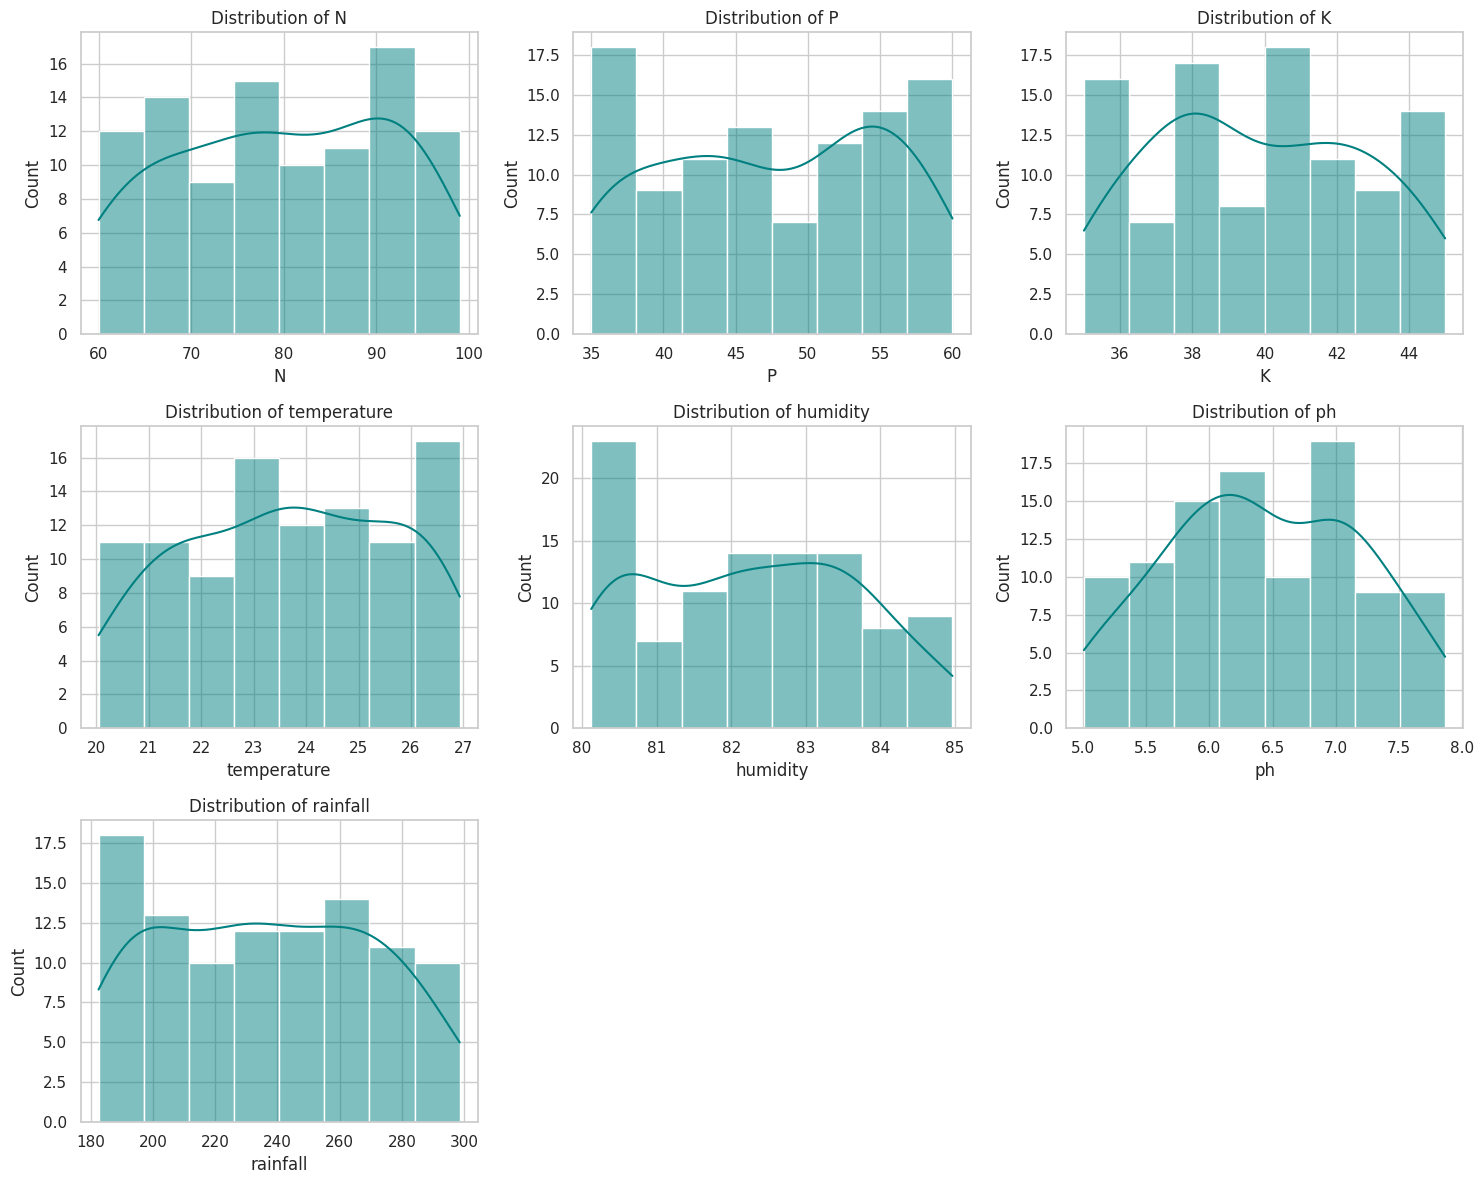

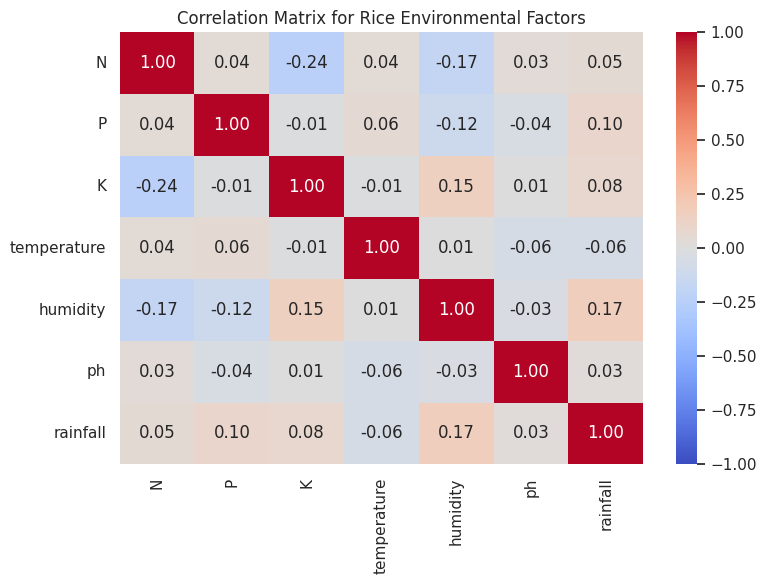

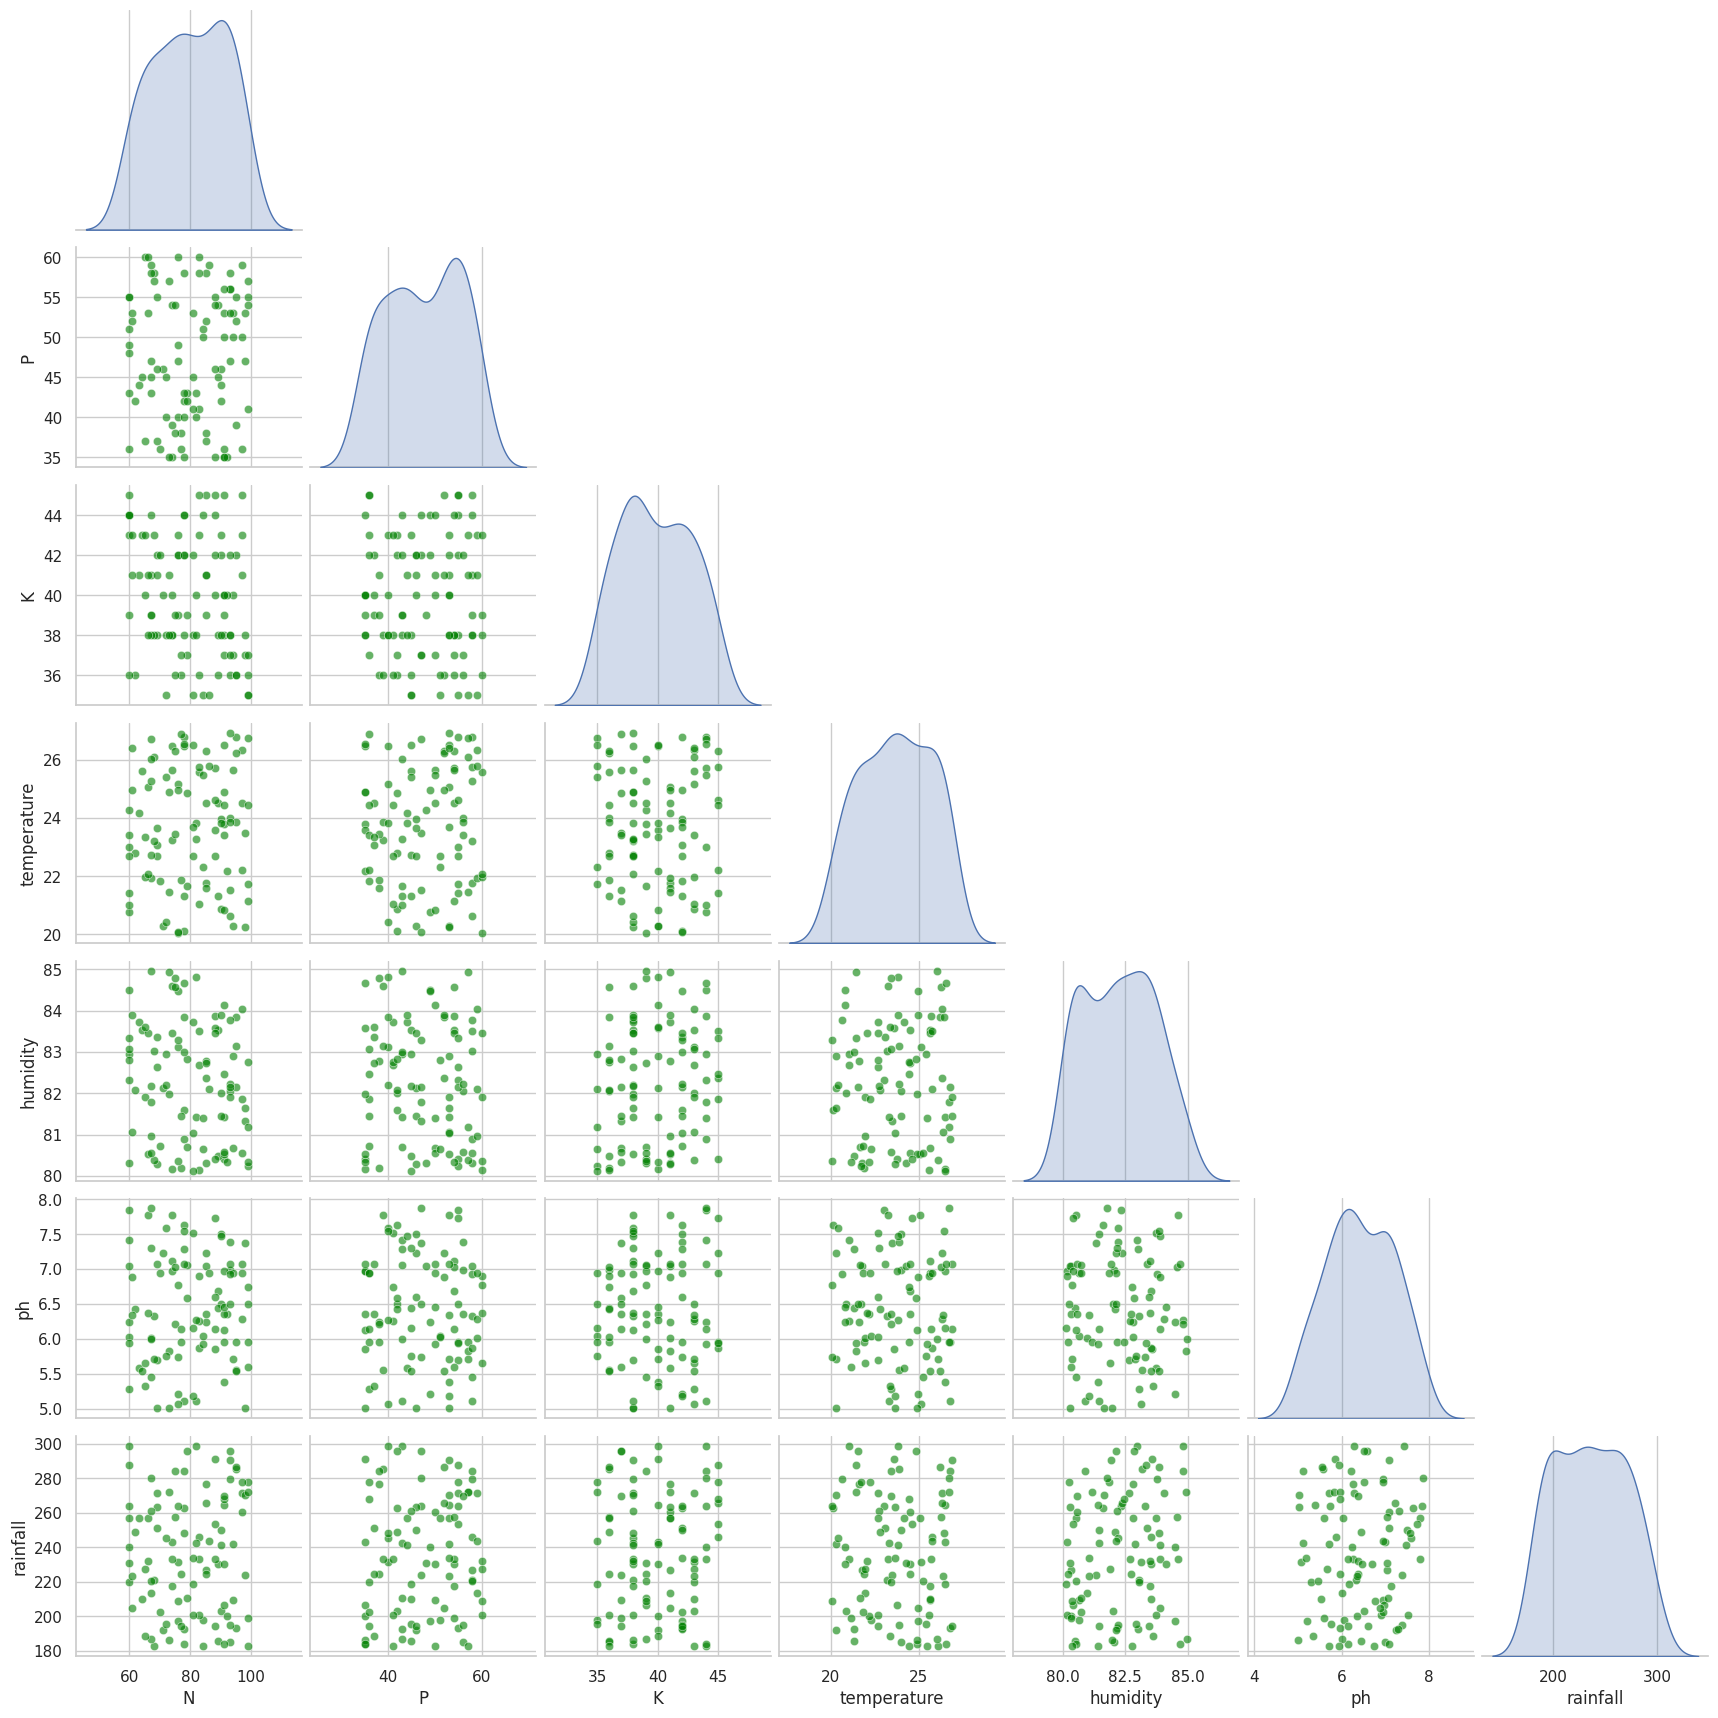

EDA completed and plots saved to 300 DPI PNGs.


In [9]:
df_rice = df_raw[df_raw['label'] == 'rice'].drop(columns=['label']).copy()

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(df_rice.columns):
    sns.histplot(df_rice[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f"Distribution of {col}")
for j in range(len(df_rice.columns), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "original_rice_distributions.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

plt.figure(figsize=(8, 6))
corr = df_rice.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix for Rice Environmental Factors")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "rice_correlation_matrix.png"), dpi=300, bbox_inches='tight')
plt.show()

plt.close()

sns.pairplot(df_rice, corner=True, diag_kind='kde', plot_kws={'alpha': 0.6, 'color': 'green'})
plt.savefig(os.path.join(Config.PLOT_DIR, "rice_pairplot.png"), dpi=300, bbox_inches='tight')
plt.show()

plt.close()

print("EDA completed and plots saved to 300 DPI PNGs.")

Generating 5000 synthetic samples to prevent overfitting...


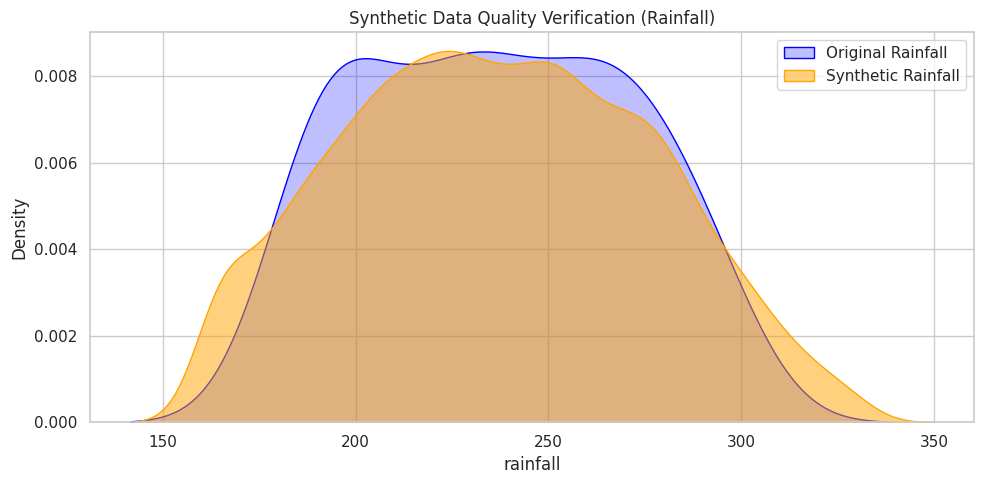

Data Prepared. Training shapes -> Nutrient X: (4000, 4), Irrigation X: (4000, 6)


In [19]:
print(f"Generating {Config.NUM_SYNTHETIC_SAMPLES} synthetic samples to prevent overfitting...")
kde = gaussian_kde(df_rice.T)
synthetic_data = kde.resample(Config.NUM_SYNTHETIC_SAMPLES, seed=Config.SEED).T

df_synth = pd.DataFrame(synthetic_data, columns=df_rice.columns)

# Clip values to logical agricultural boundaries based on original min/max +- 10%
for col in df_rice.columns:
    min_val = df_rice[col].min() * 0.9
    max_val = df_rice[col].max() * 1.1
    df_synth[col] = np.clip(df_synth[col], min_val, max_val)

# Verify synthetic data distribution matches original
plt.figure(figsize=(10, 5))
sns.kdeplot(df_rice['rainfall'], label='Original Rainfall', fill=True, color='blue')
sns.kdeplot(df_synth['rainfall'], label='Synthetic Rainfall', fill=True, color='orange', alpha=0.5)
plt.title("Synthetic Data Quality Verification (Rainfall)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "synthetic_data_verification.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Setup Data for Model 1: Nutrient Regressors (N, P, K)
X_nut = df_synth[['temperature', 'humidity', 'ph', 'rainfall']]
y_nut = df_synth[['N', 'P', 'K']]

# Setup Data for Model 2: Irrigation Regressor
X_irr = df_synth[['temperature', 'humidity', 'ph', 'N', 'P', 'K']]
y_irr = df_synth['rainfall']

# Scaling
scaler_nut_X = StandardScaler()
scaler_nut_y = StandardScaler()
X_nut_scaled = scaler_nut_X.fit_transform(X_nut)
y_nut_scaled = scaler_nut_y.fit_transform(y_nut)

scaler_irr_X = StandardScaler()
scaler_irr_y = StandardScaler()
X_irr_scaled = scaler_irr_X.fit_transform(X_irr)
y_irr_scaled = scaler_irr_y.fit_transform(y_irr.values.reshape(-1, 1)).flatten()

# Splits
X_n_train, X_n_test, y_n_train, y_n_test = train_test_split(X_nut_scaled, y_nut_scaled, test_size=Config.TEST_SIZE, random_state=Config.SEED)
X_i_train, X_i_test, y_i_train, y_i_test = train_test_split(X_irr_scaled, y_irr_scaled, test_size=Config.TEST_SIZE, random_state=Config.SEED)

print(f"Data Prepared. Training shapes -> Nutrient X: {X_n_train.shape}, Irrigation X: {X_i_train.shape}")



--- Starting Model Training ---
>>> Training Nutrient Model: N
>>> Training Nutrient Model: P
>>> Training Nutrient Model: K
>>> Training Irrigation Model


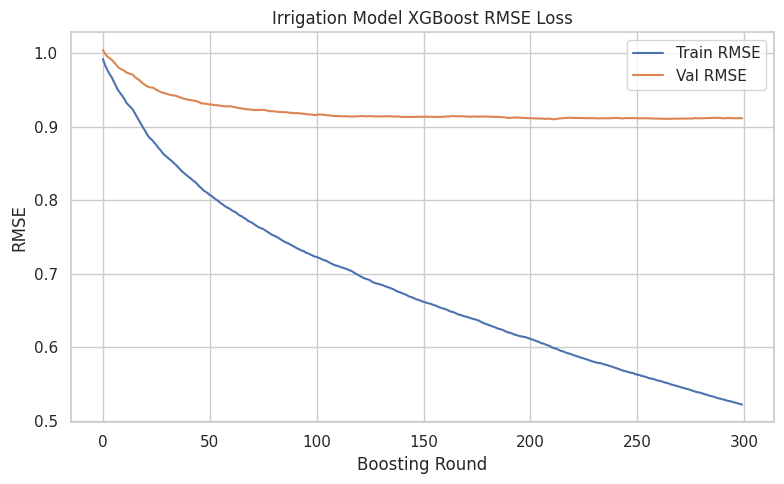

In [20]:
print("\n--- Starting Model Training ---")

# Train Nutrient Models (N, P, K)
nutrient_models = {}
targets = [('N', 0), ('P', 1), ('K', 2)]

for name, idx in targets:
    print(f">>> Training Nutrient Model: {name}")
    model = xgb.XGBRegressor(**Config.XGB_PARAMS)
    model.fit(
        X_n_train, y_n_train[:, idx],
        eval_set=[(X_n_train, y_n_train[:, idx]), (X_n_test, y_n_test[:, idx])],
        verbose=False
    )
    nutrient_models[name] = model

print(">>> Training Irrigation Model")
best_irrigation_model = xgb.XGBRegressor(**Config.XGB_PARAMS)
best_irrigation_model.fit(
    X_i_train, y_i_train,
    eval_set=[(X_i_train, y_i_train), (X_i_test, y_i_test)],
    verbose=False
)

# Extract training history for plotting
results = best_irrigation_model.evals_result()
# Depending on the XGBoost version, eval keys might be 'validation_0' or 'learn'
train_key = list(results.keys())[0]
val_key = list(results.keys())[1] if len(results.keys()) > 1 else train_key

train_rmse = results[train_key]['rmse']
val_rmse = results[val_key]['rmse']

epochs_irr = len(train_rmse)
x_axis = range(0, epochs_irr)

plt.figure(figsize=(8, 5))
plt.plot(x_axis, train_rmse, label='Train RMSE')
plt.plot(x_axis, val_rmse, label='Val RMSE')
plt.legend()
plt.title('Irrigation Model XGBoost RMSE Loss')
plt.ylabel('RMSE')
plt.xlabel('Boosting Round')
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "irrigation_training_loss.png"), dpi=300)
plt.show()
plt.close()


--- Evaluating Models ---
Nutrient Model (Combined) -> R2: 0.0595 | RMSE: 9.3013 | MAE: 6.9568
Irrigation Model -> R2: 0.1776 | RMSE: 35.9729 | MAE: 29.6343


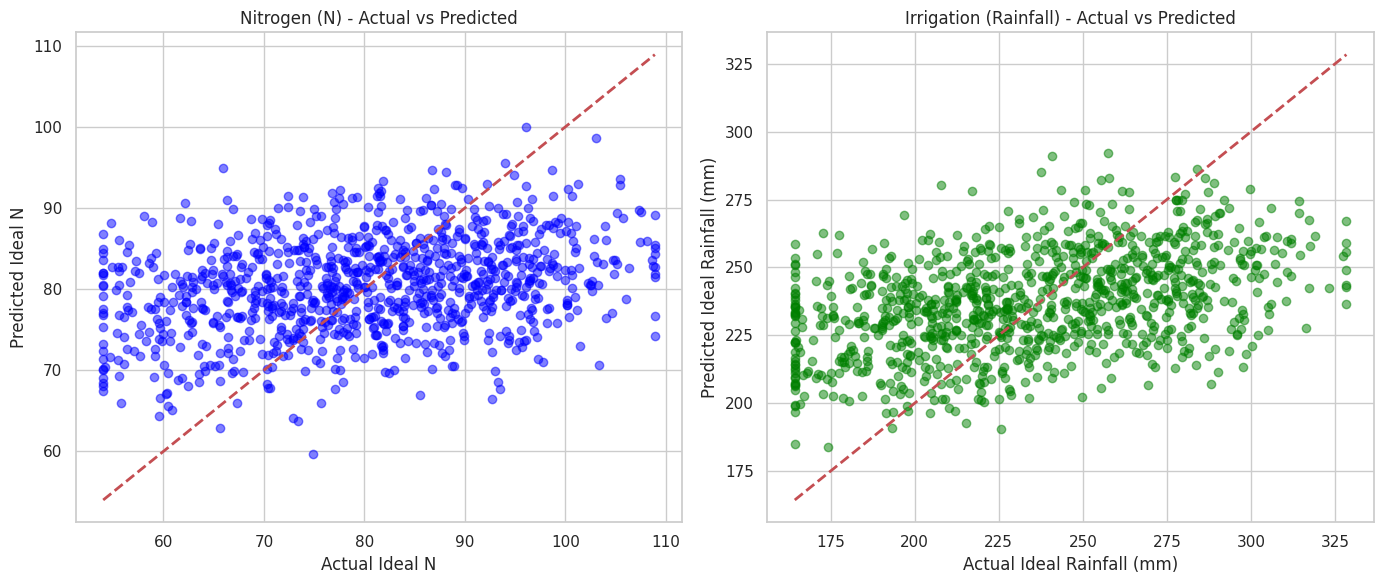

In [21]:
print("\n--- Evaluating Models ---")

y_n_pred_scaled = np.column_stack([
    nutrient_models['N'].predict(X_n_test),
    nutrient_models['P'].predict(X_n_test),
    nutrient_models['K'].predict(X_n_test)
])

y_n_pred = scaler_nut_y.inverse_transform(y_n_pred_scaled)
y_n_true = scaler_nut_y.inverse_transform(y_n_test)

nut_r2 = r2_score(y_n_true, y_n_pred, multioutput='variance_weighted')
nut_rmse = np.sqrt(mean_squared_error(y_n_true, y_n_pred))
nut_mae = mean_absolute_error(y_n_true, y_n_pred)

print(f"Nutrient Model (Combined) -> R2: {nut_r2:.4f} | RMSE: {nut_rmse:.4f} | MAE: {nut_mae:.4f}")

y_i_pred_scaled = best_irrigation_model.predict(X_i_test)
y_i_pred = scaler_irr_y.inverse_transform(y_i_pred_scaled.reshape(-1, 1)).flatten()
y_i_true = scaler_irr_y.inverse_transform(y_i_test.reshape(-1, 1)).flatten()

irr_r2 = r2_score(y_i_true, y_i_pred)
irr_rmse = np.sqrt(mean_squared_error(y_i_true, y_i_pred))
irr_mae = mean_absolute_error(y_i_true, y_i_pred)

print(f"Irrigation Model -> R2: {irr_r2:.4f} | RMSE: {irr_rmse:.4f} | MAE: {irr_mae:.4f}")

# Scatter Plots: Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# N Prediction Scatter
axes[0].scatter(y_n_true[:, 0], y_n_pred[:, 0], alpha=0.5, color='blue')
axes[0].plot([y_n_true[:, 0].min(), y_n_true[:, 0].max()], [y_n_true[:, 0].min(), y_n_true[:, 0].max()], 'r--', lw=2)
axes[0].set_title('Nitrogen (N) - Actual vs Predicted')
axes[0].set_xlabel('Actual Ideal N')
axes[0].set_ylabel('Predicted Ideal N')

# Irrigation Prediction Scatter
axes[1].scatter(y_i_true, y_i_pred, alpha=0.5, color='green')
axes[1].plot([y_i_true.min(), y_i_true.max()], [y_i_true.min(), y_i_true.max()], 'r--', lw=2)
axes[1].set_title('Irrigation (Rainfall) - Actual vs Predicted')
axes[1].set_xlabel('Actual Ideal Rainfall (mm)')
axes[1].set_ylabel('Predicted Ideal Rainfall (mm)')

plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "actual_vs_predicted.png"), dpi=300)
plt.show()
plt.close()


--- Generating SHAP Explainability Reports ---


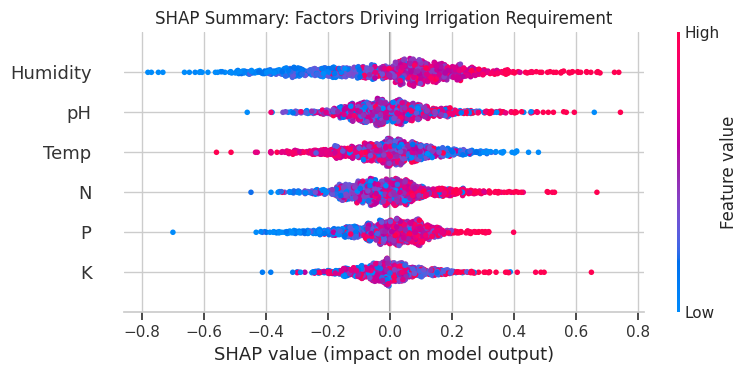

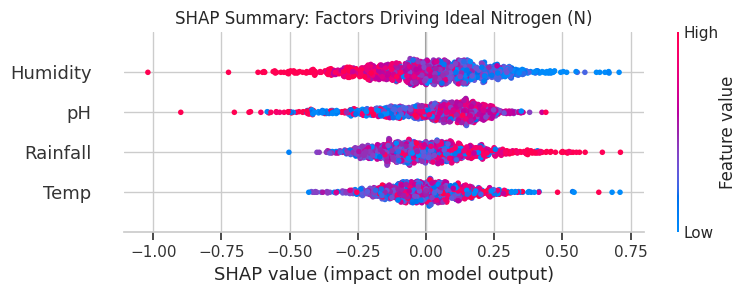

SHAP visualizations generated successfully.


In [22]:
print("\n--- Generating SHAP Explainability Reports ---")

explainer_irr = shap.TreeExplainer(best_irrigation_model)
shap_values_irr = explainer_irr.shap_values(X_i_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_irr, X_i_test, feature_names=['Temp', 'Humidity', 'pH', 'N', 'P', 'K'], show=False)
plt.title("SHAP Summary: Factors Driving Irrigation Requirement")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "shap_irrigation_summary.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

explainer_n = shap.TreeExplainer(nutrient_models['N'])
shap_values_n = explainer_n.shap_values(X_n_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_n, X_n_test, feature_names=['Temp', 'Humidity', 'pH', 'Rainfall'], show=False)
plt.title("SHAP Summary: Factors Driving Ideal Nitrogen (N)")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "shap_nitrogen_summary.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("SHAP visualizations generated successfully.")

PUBLICATION QUALITY VISUALIZATION BLOCK

--- DATASET ANALYSIS ---


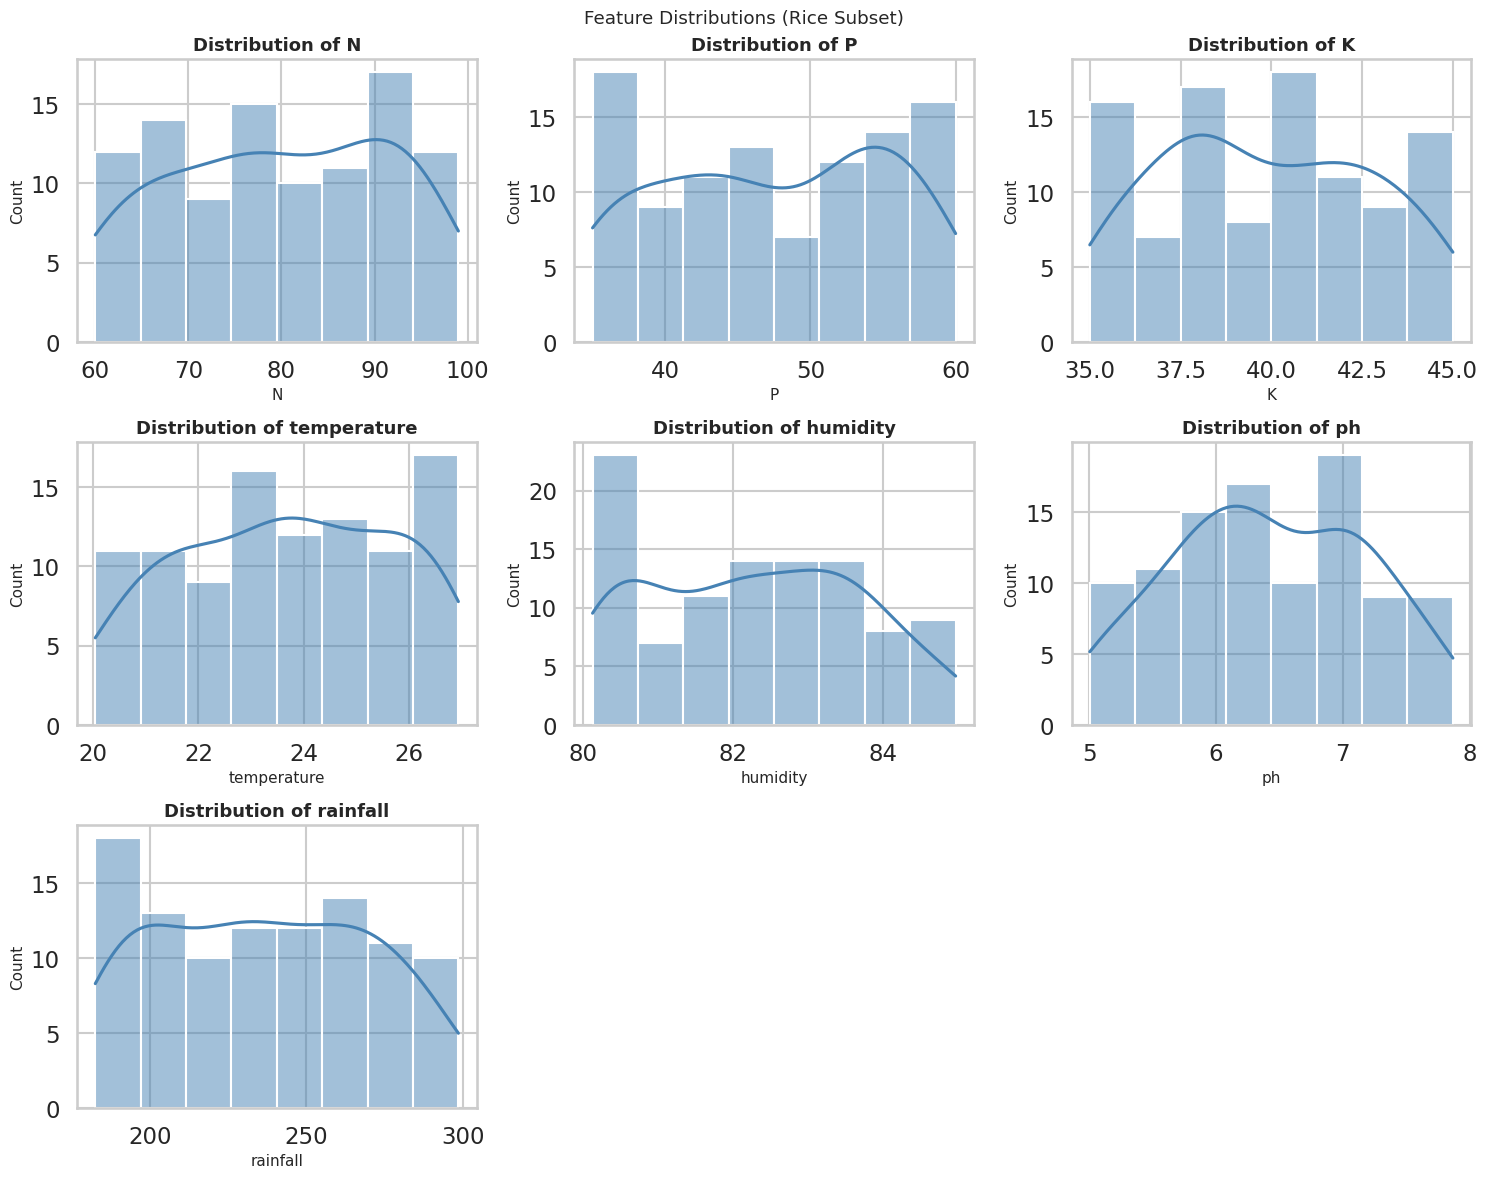

✓ Figure saved: ./output/phase_1_3/plots/01_feature_distributions.png


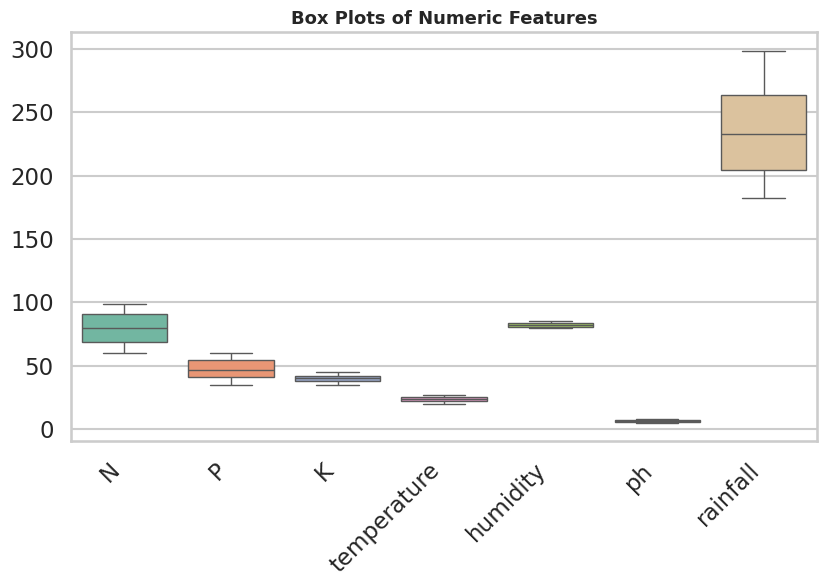

✓ Figure saved: ./output/phase_1_3/plots/02_boxplots.png


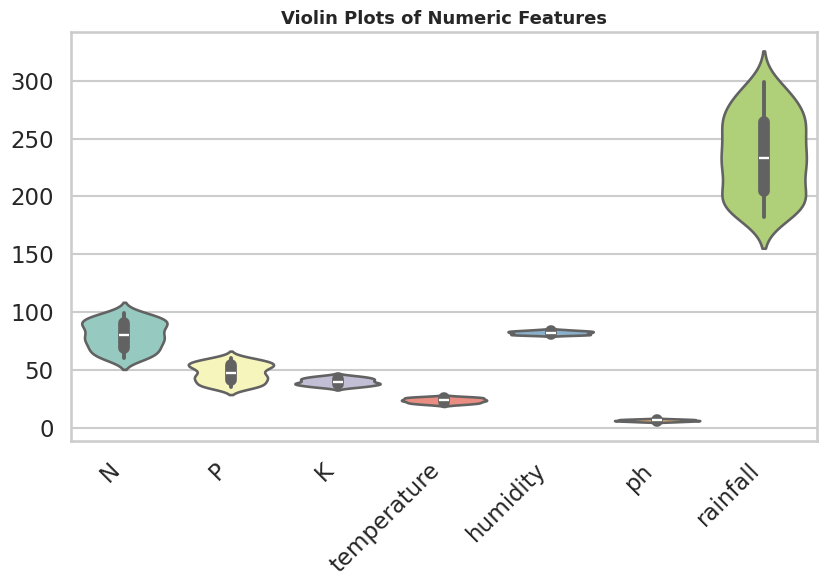

✓ Figure saved: ./output/phase_1_3/plots/03_violinplots.png


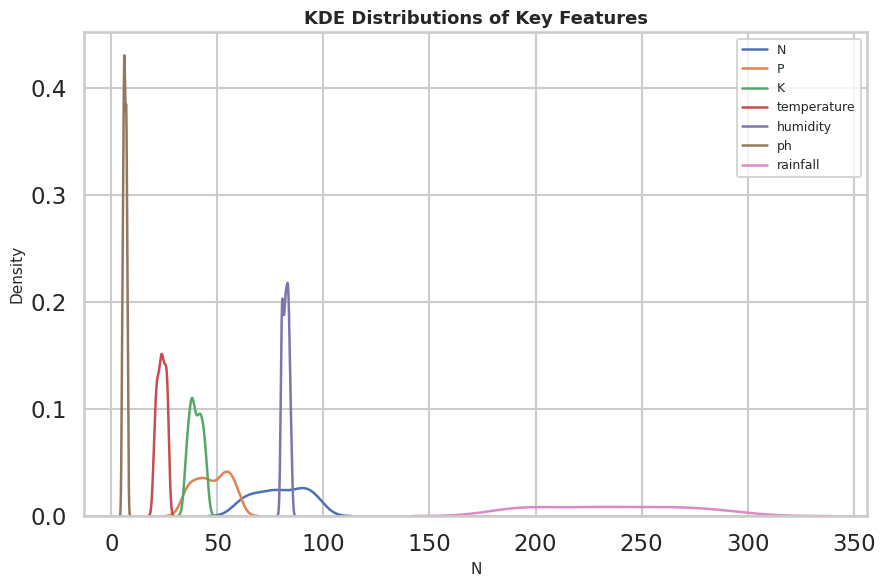

✓ Figure saved: ./output/phase_1_3/plots/04_kde_distributions.png


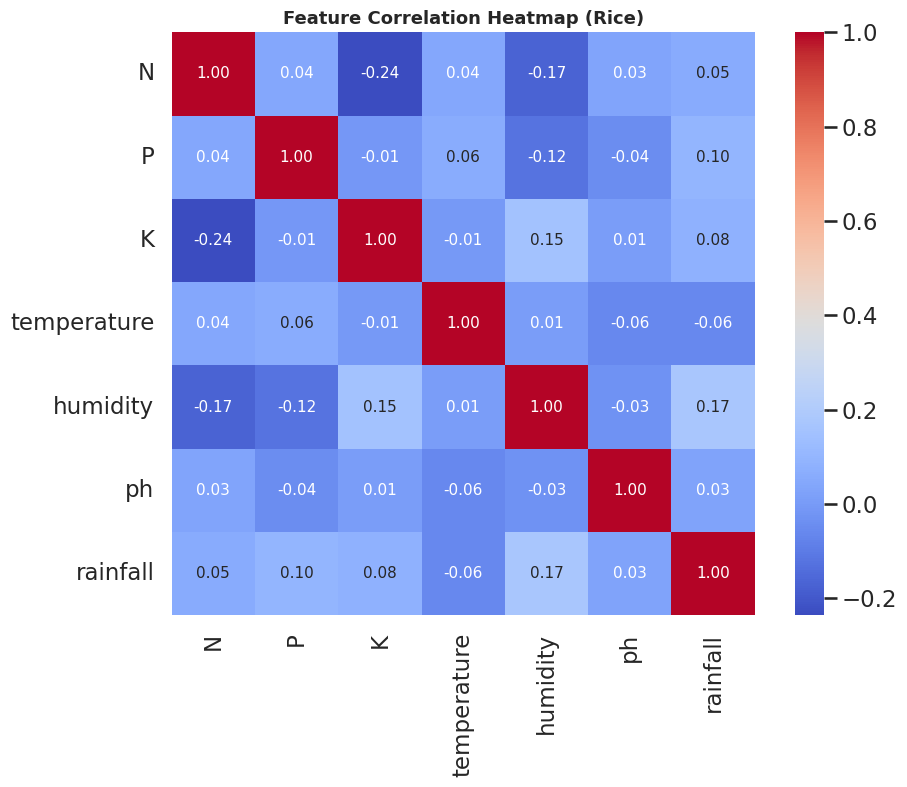

✓ Figure saved: ./output/phase_1_3/plots/05_correlation_heatmap.png


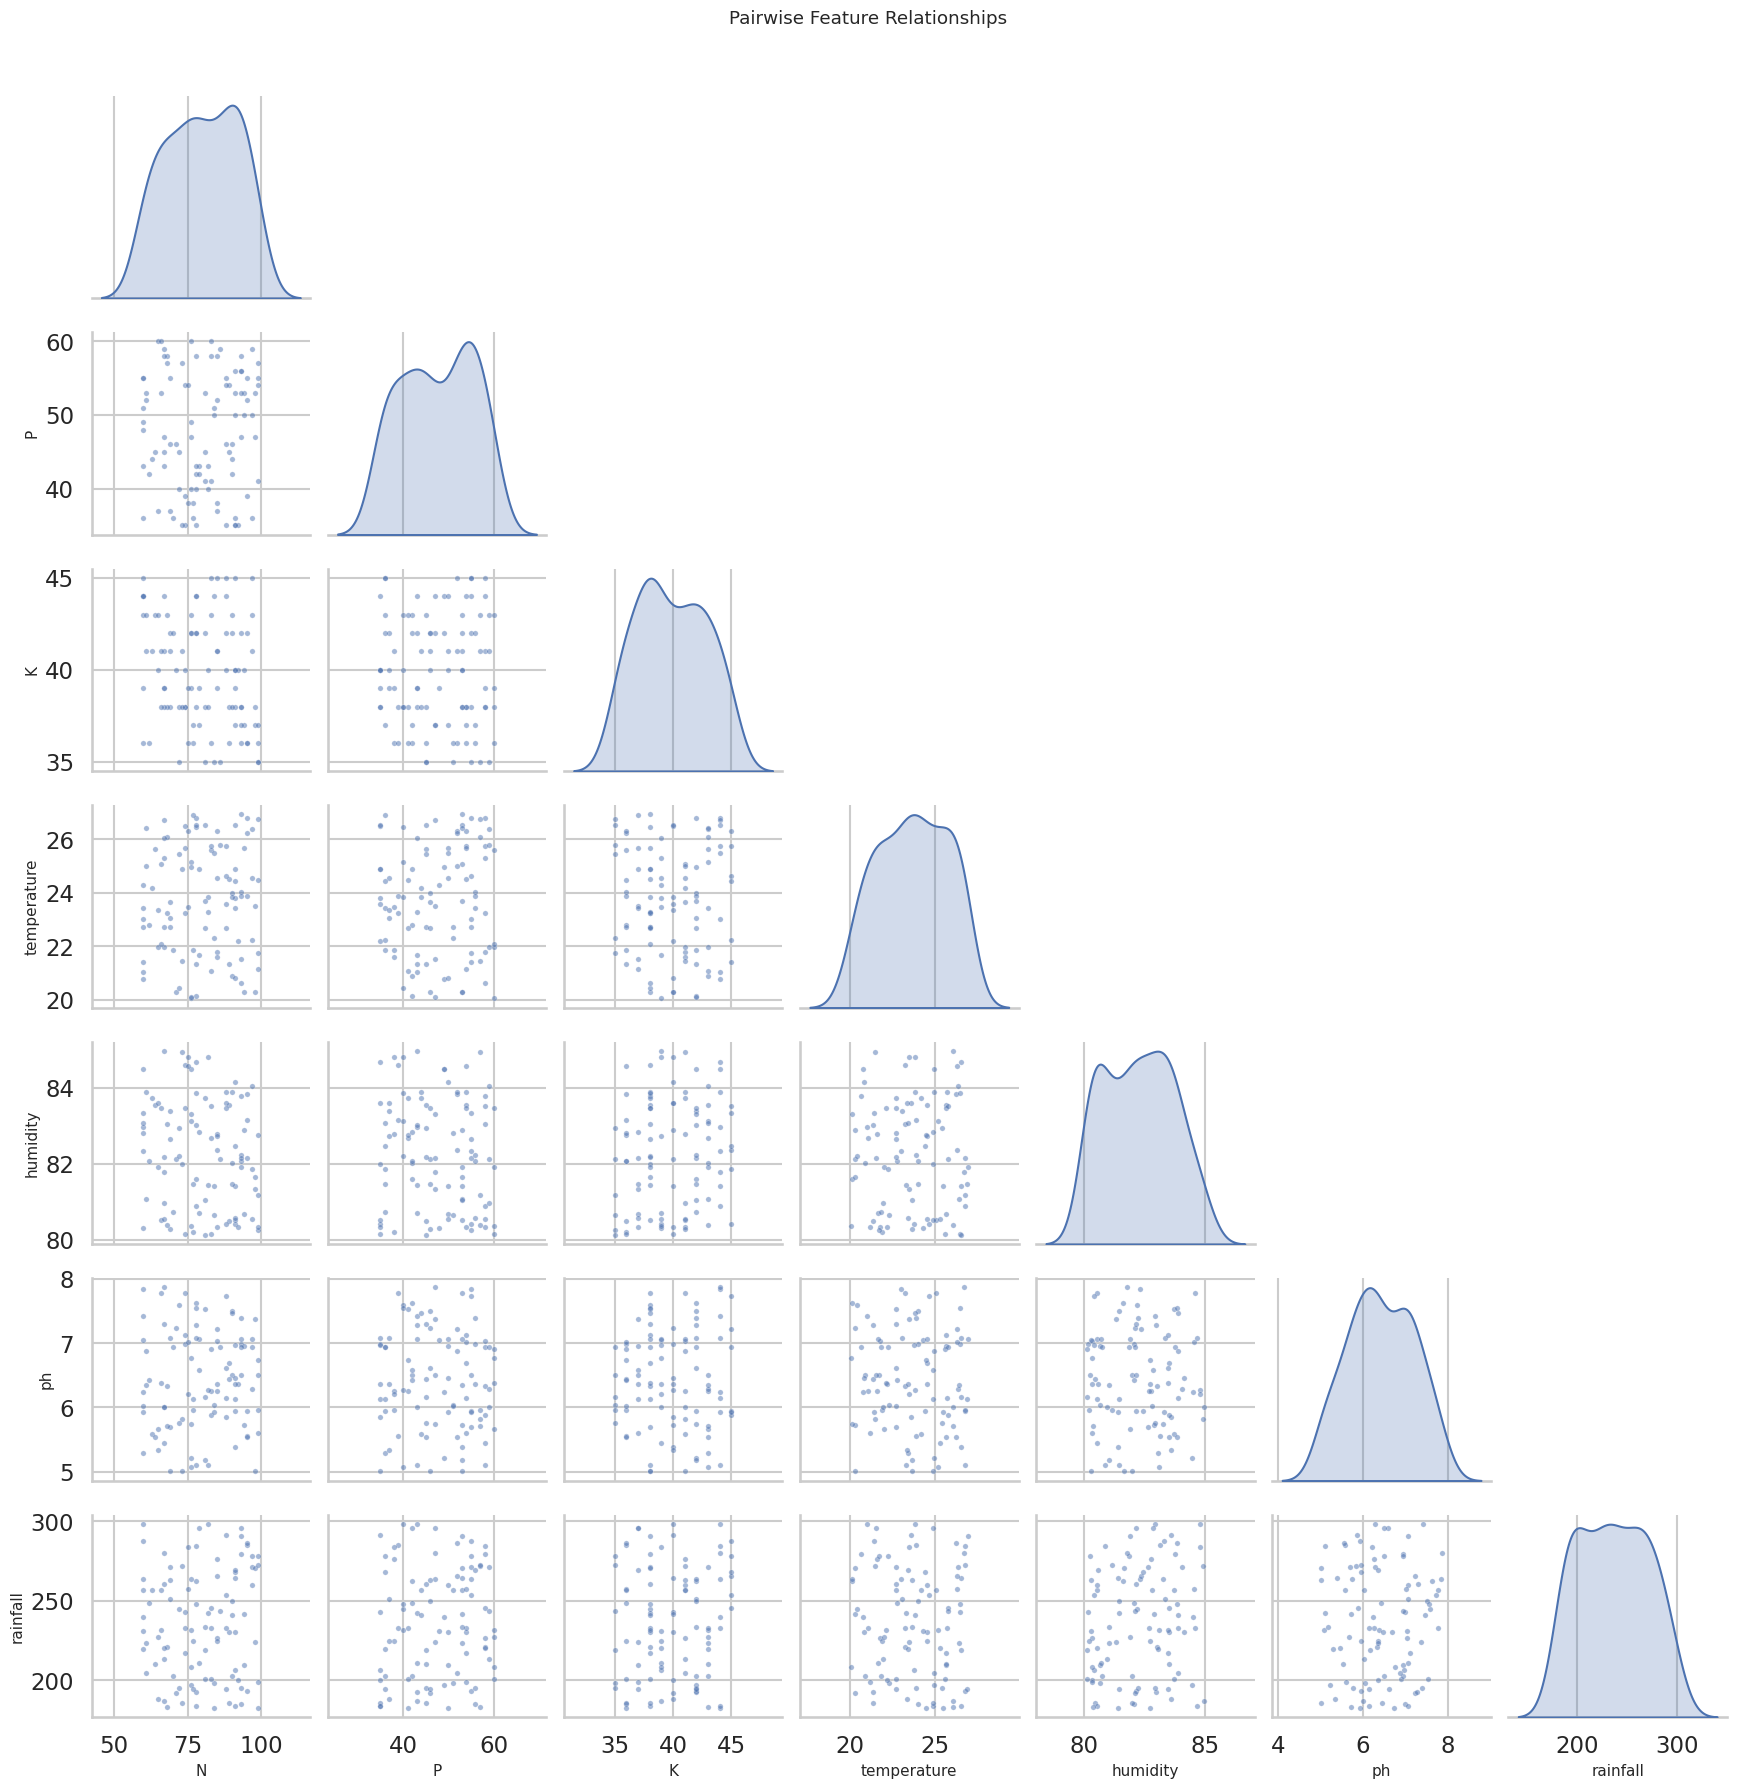

✓ Figure saved: ./output/phase_1_3/plots/06_pairplot.png


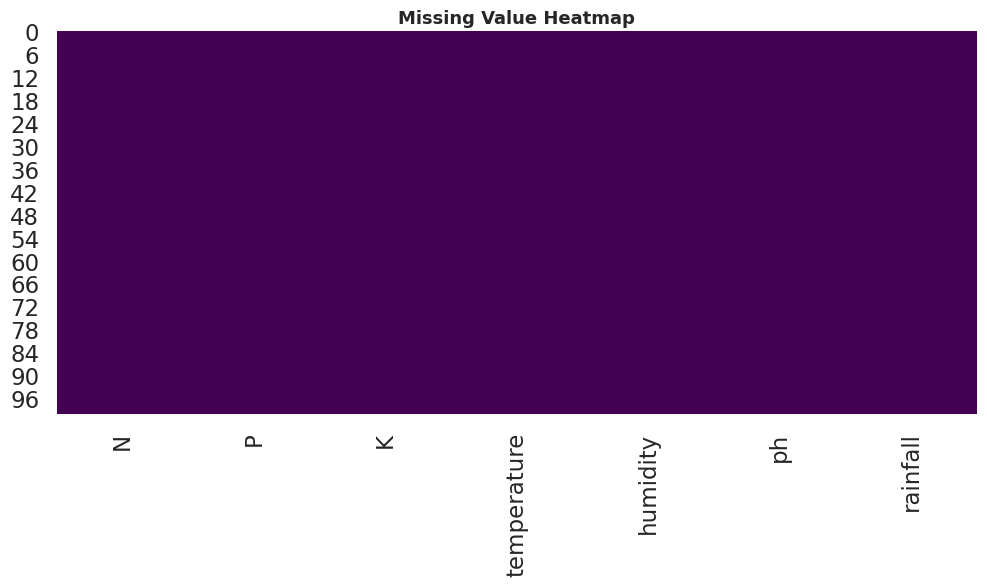

✓ Figure saved: ./output/phase_1_3/plots/07_missing_value_heatmap.png


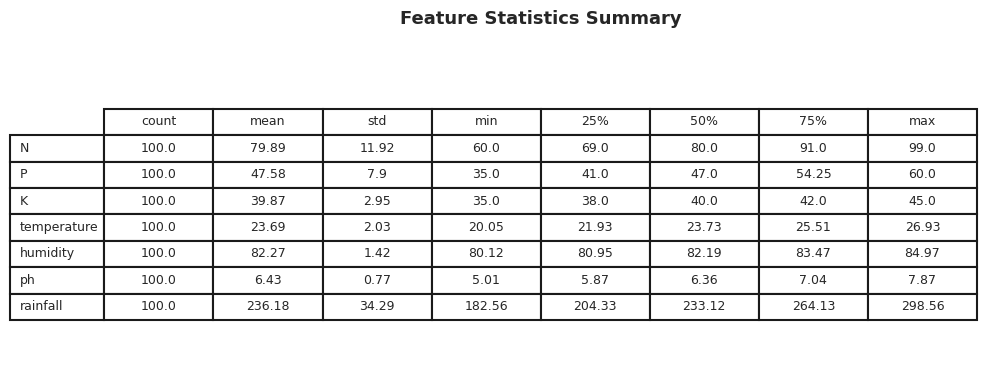

✓ Figure saved: ./output/phase_1_3/plots/08_feature_statistics.png


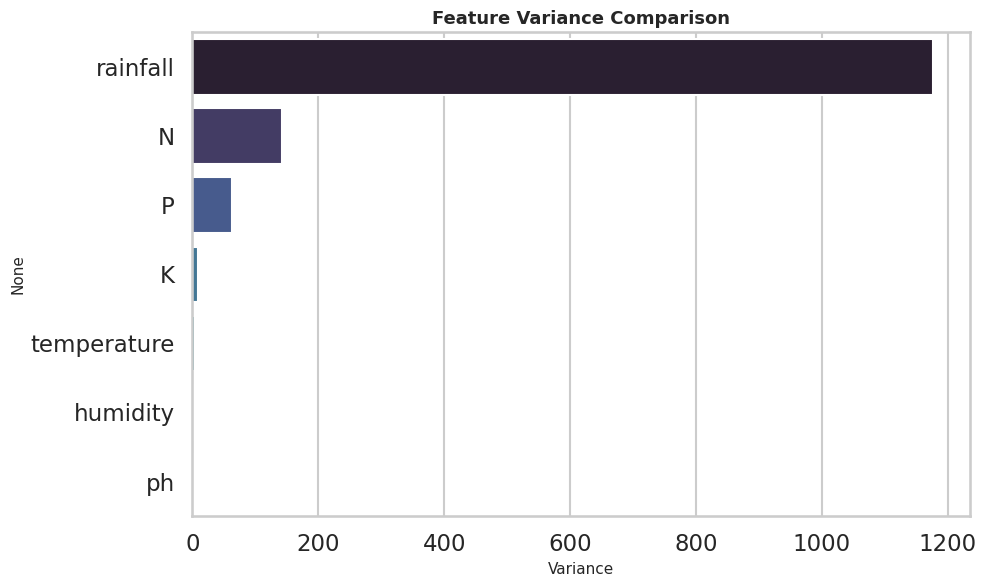

✓ Figure saved: ./output/phase_1_3/plots/09_feature_variance_comparison.png

--- SYNTHETIC DATA ANALYSIS ---


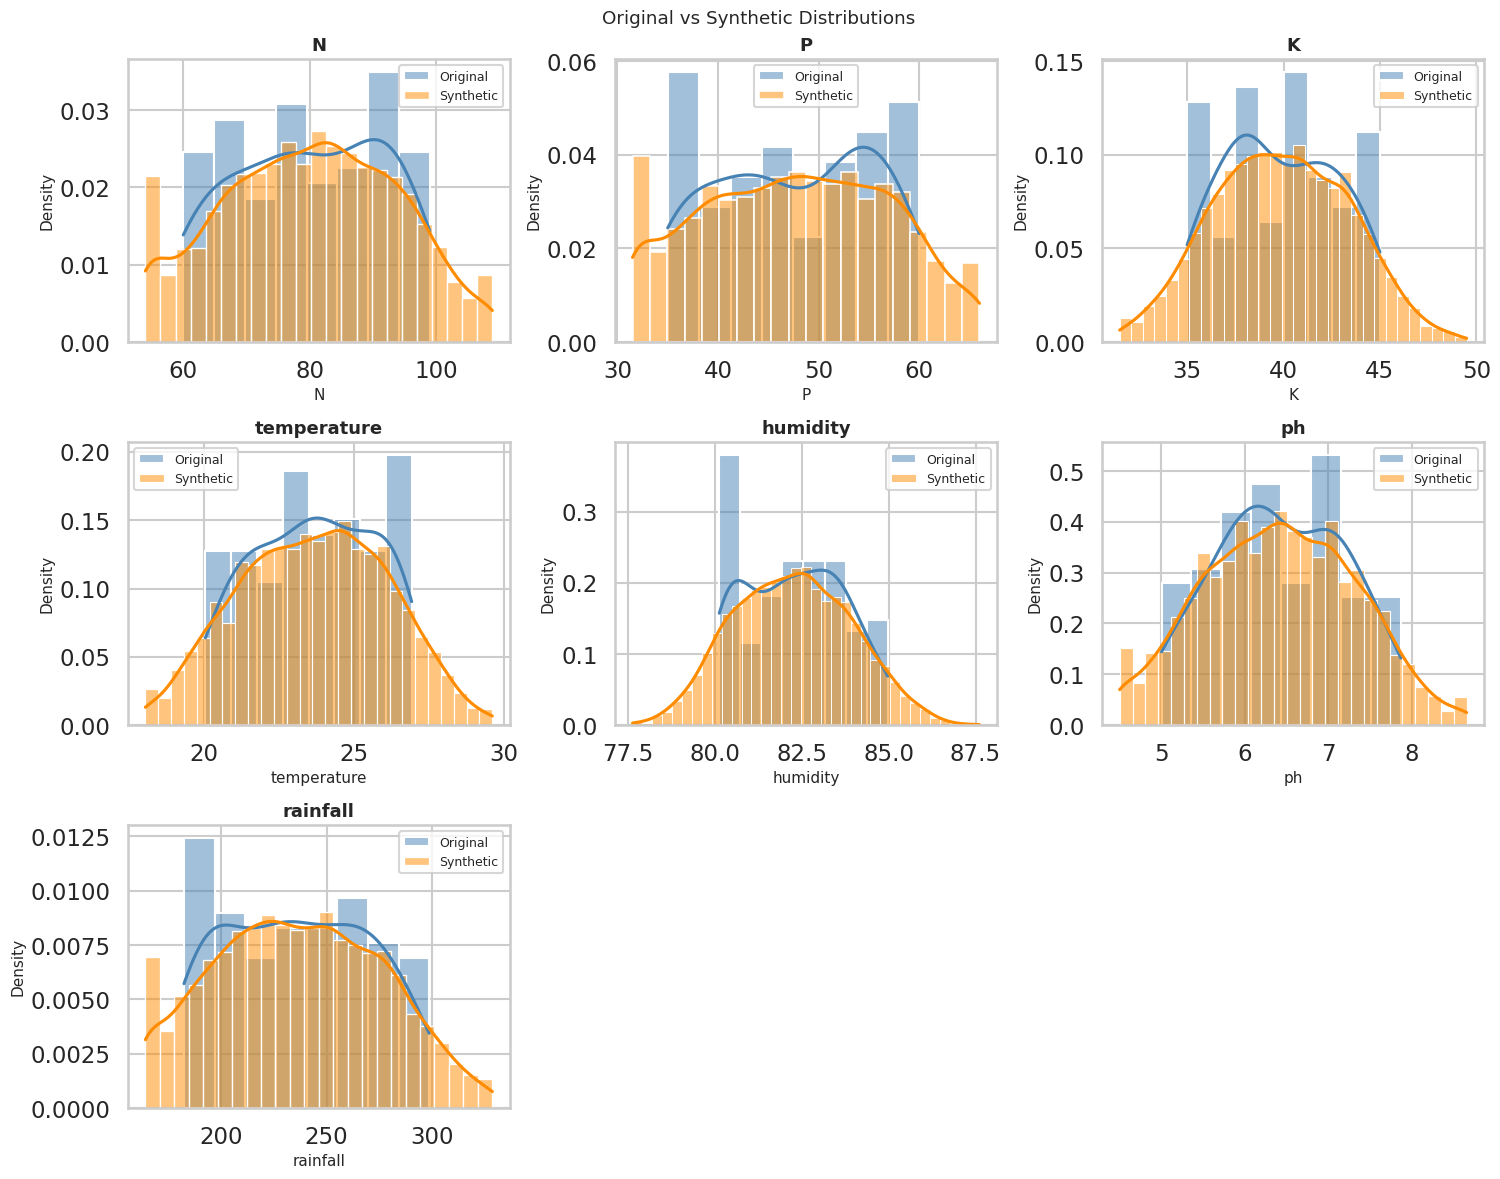

✓ Figure saved: ./output/phase_1_3/plots/10_original_vs_synthetic_distributions.png


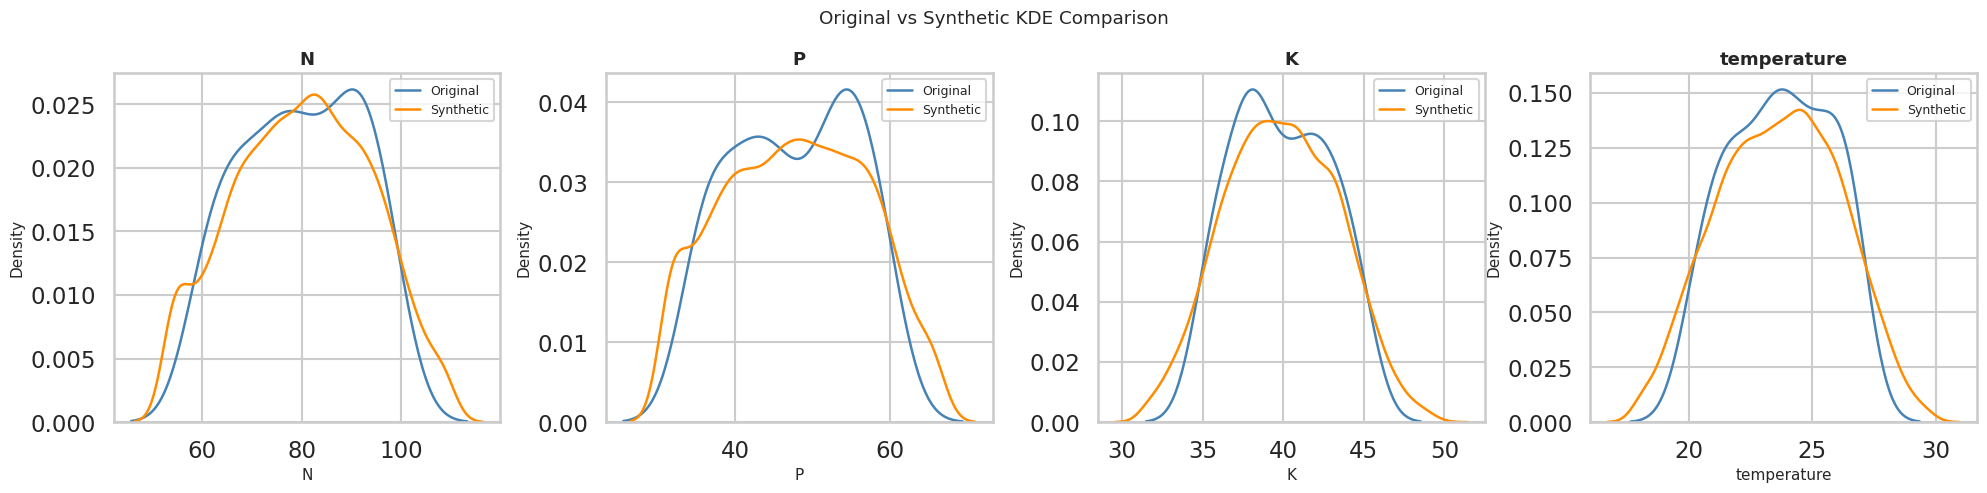

✓ Figure saved: ./output/phase_1_3/plots/11_original_vs_synthetic_kde.png


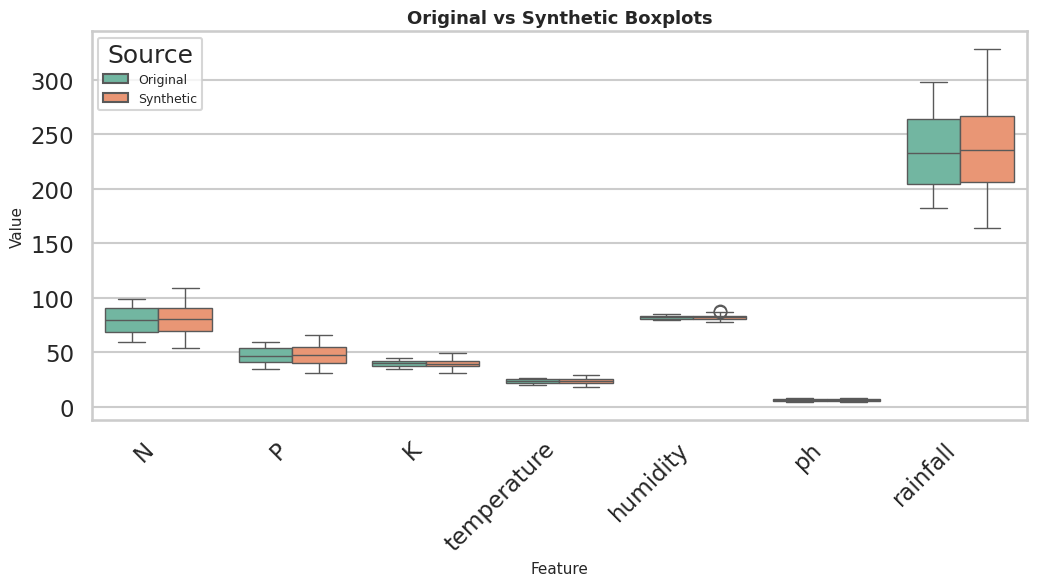

✓ Figure saved: ./output/phase_1_3/plots/12_original_vs_synthetic_boxplots.png


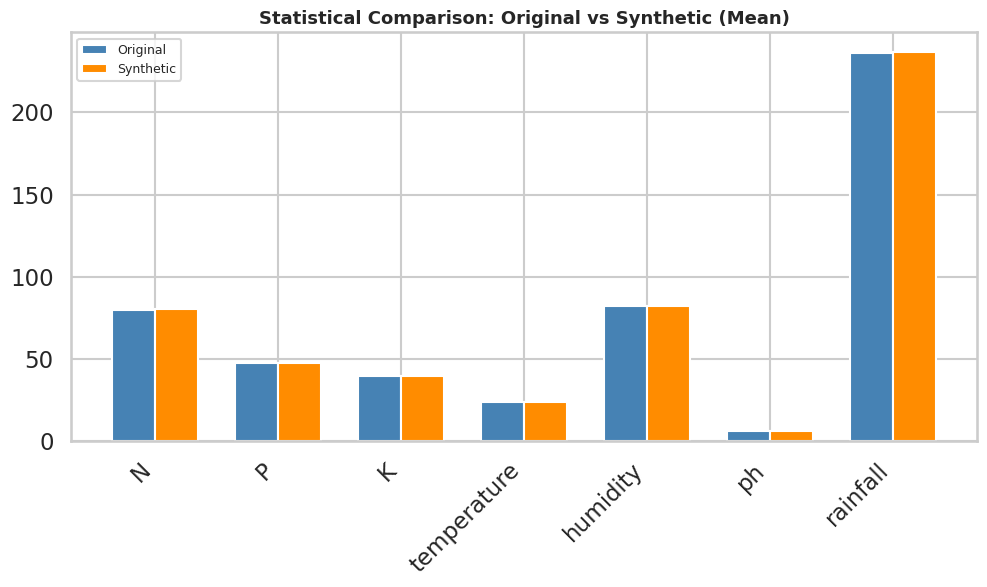

✓ Figure saved: ./output/phase_1_3/plots/13_statistical_comparison.png

--- MODEL TRAINING ---


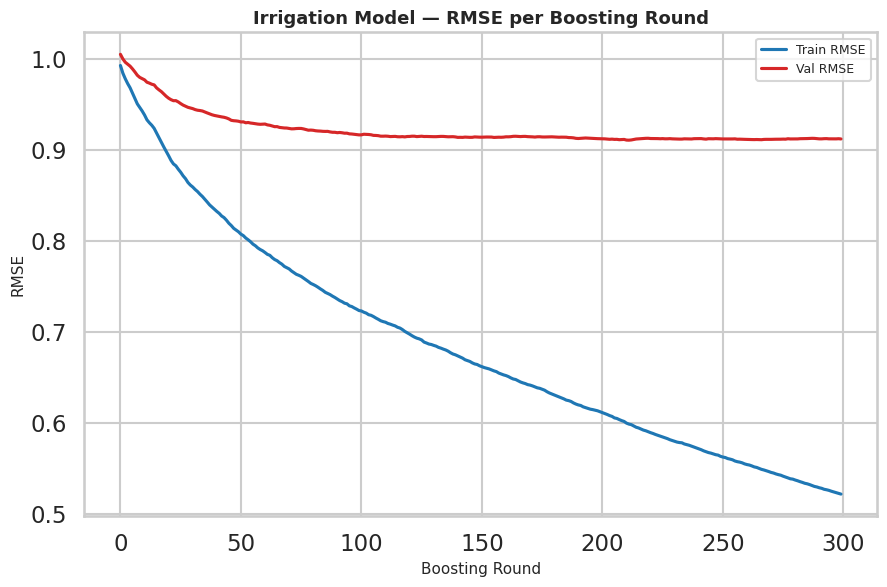

✓ Figure saved: ./output/phase_1_3/plots/14_irrigation_rmse_curve.png


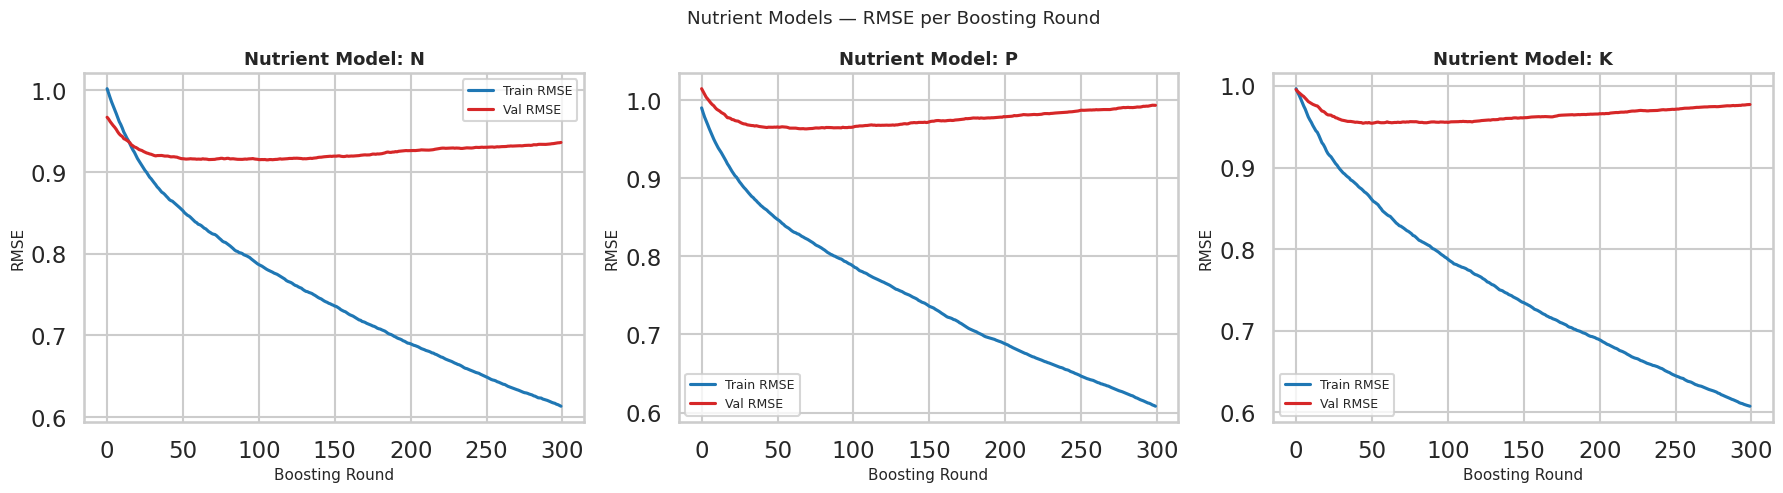

✓ Figure saved: ./output/phase_1_3/plots/15_nutrient_rmse_curves.png


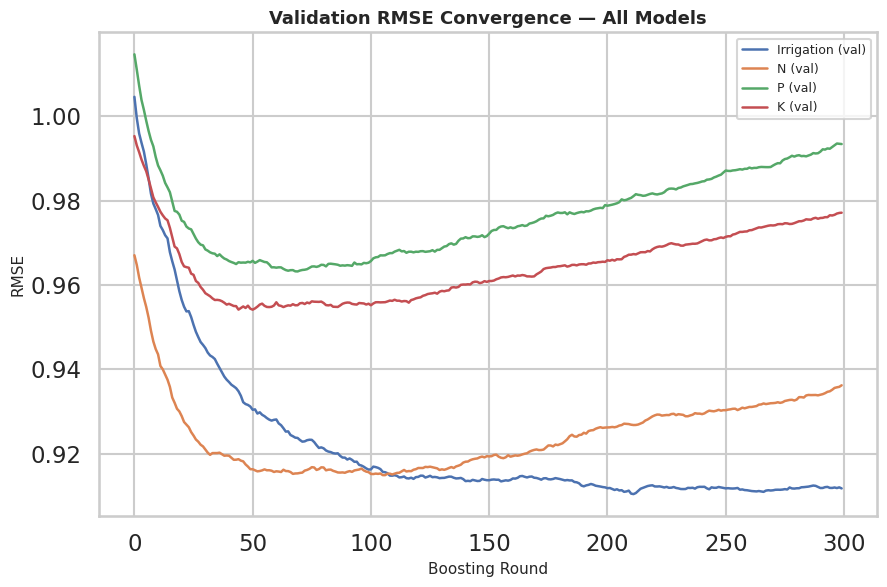

✓ Figure saved: ./output/phase_1_3/plots/16_rmse_convergence_all_models.png

--- MODEL EVALUATION ---


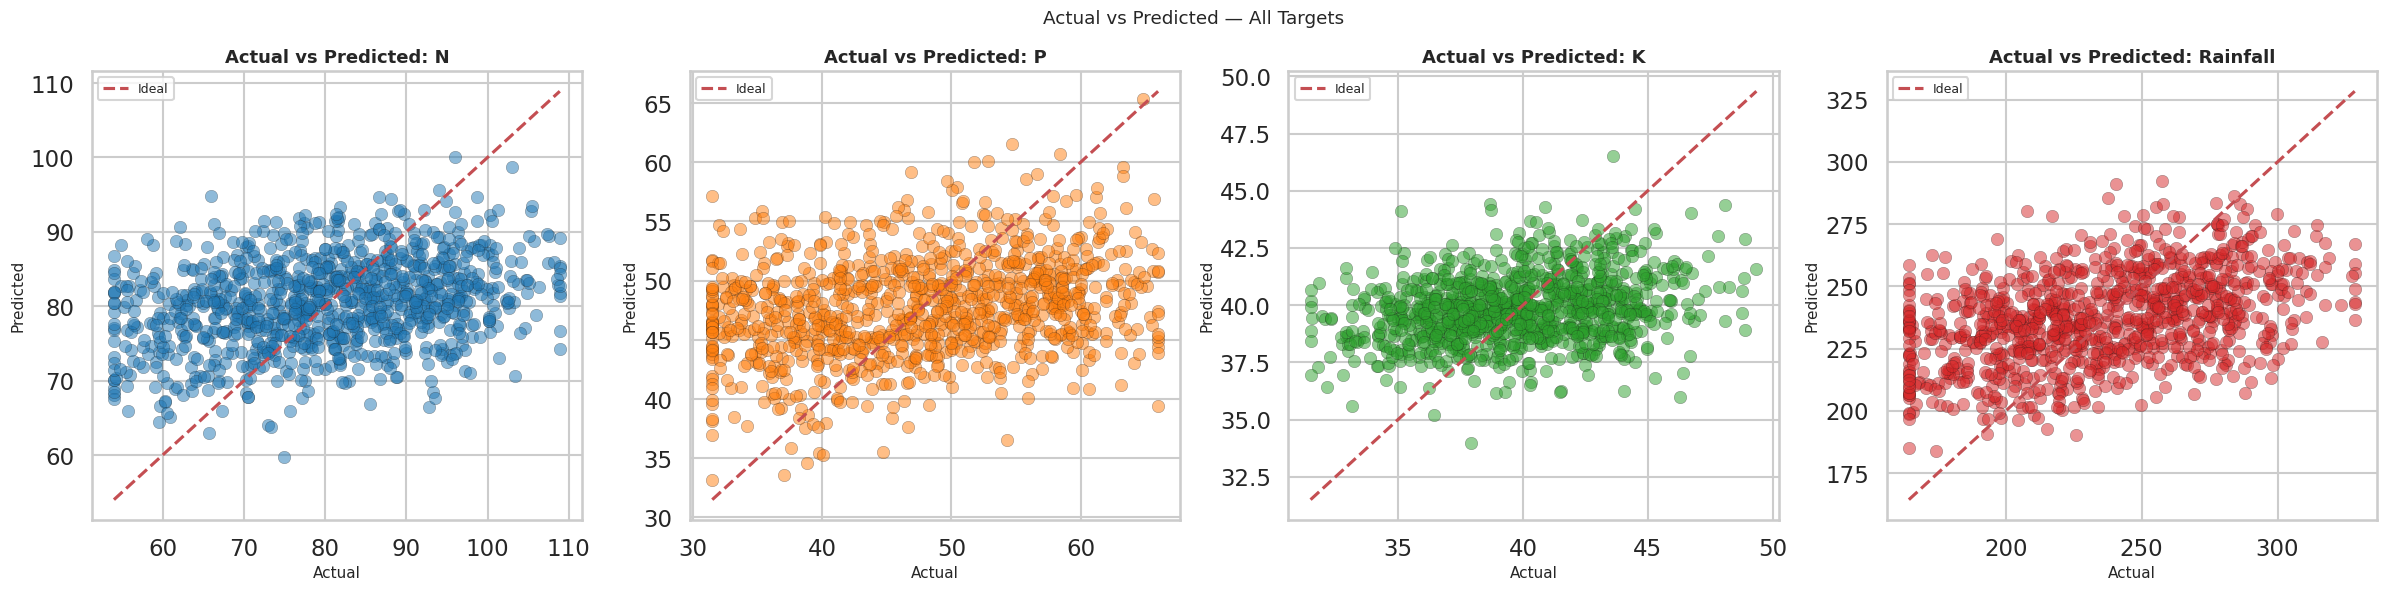

✓ Figure saved: ./output/phase_1_3/plots/17_actual_vs_predicted_all.png


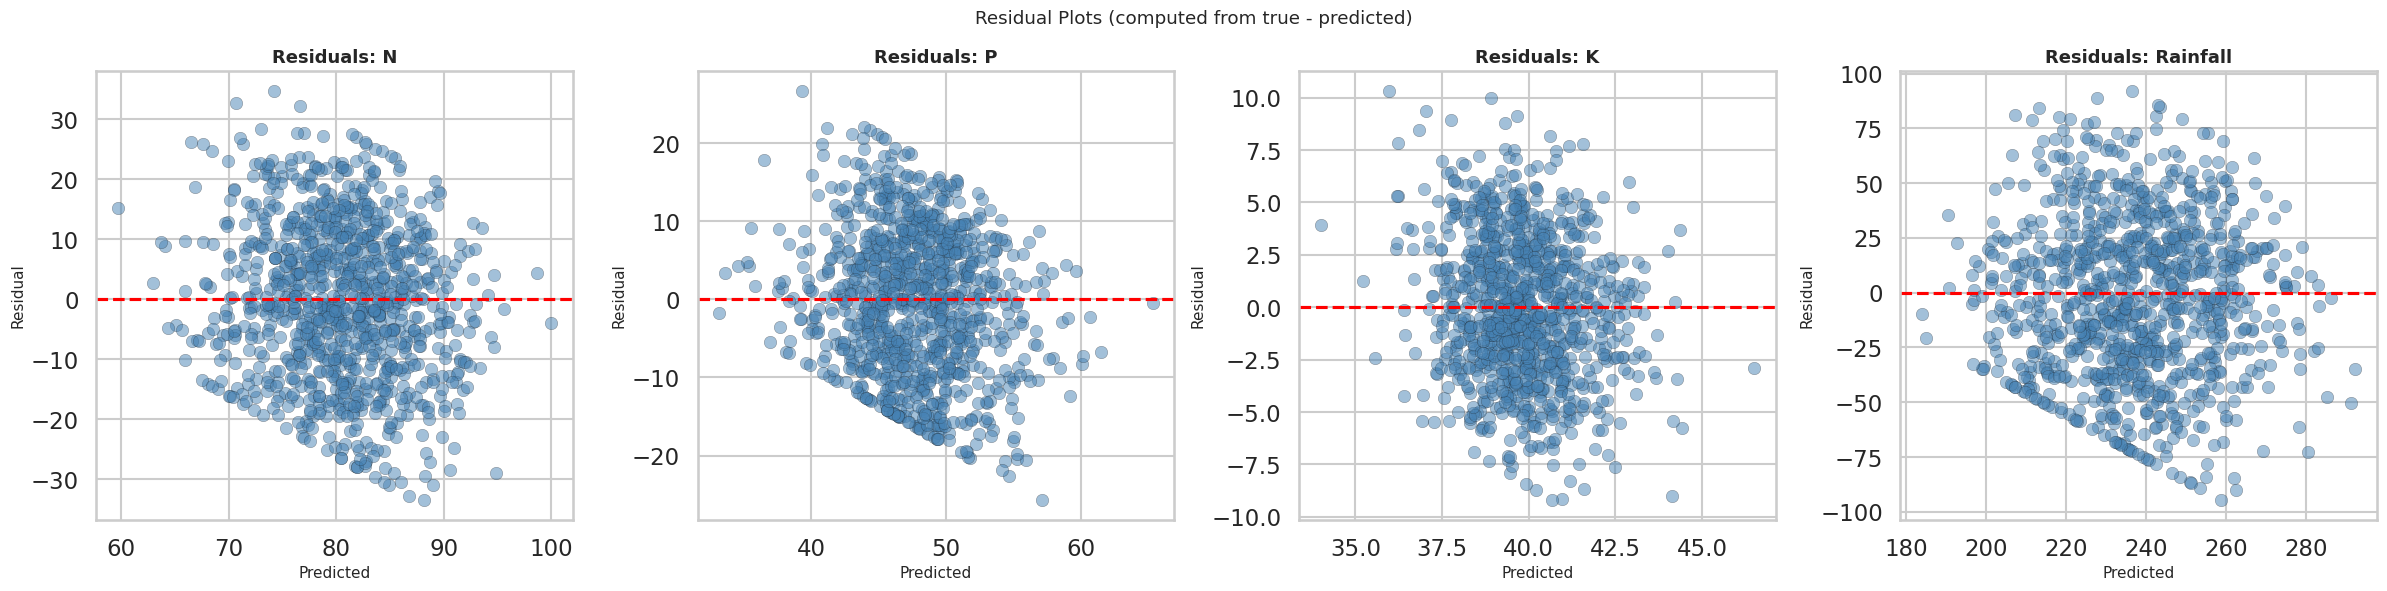

✓ Figure saved: ./output/phase_1_3/plots/18_residual_plots.png


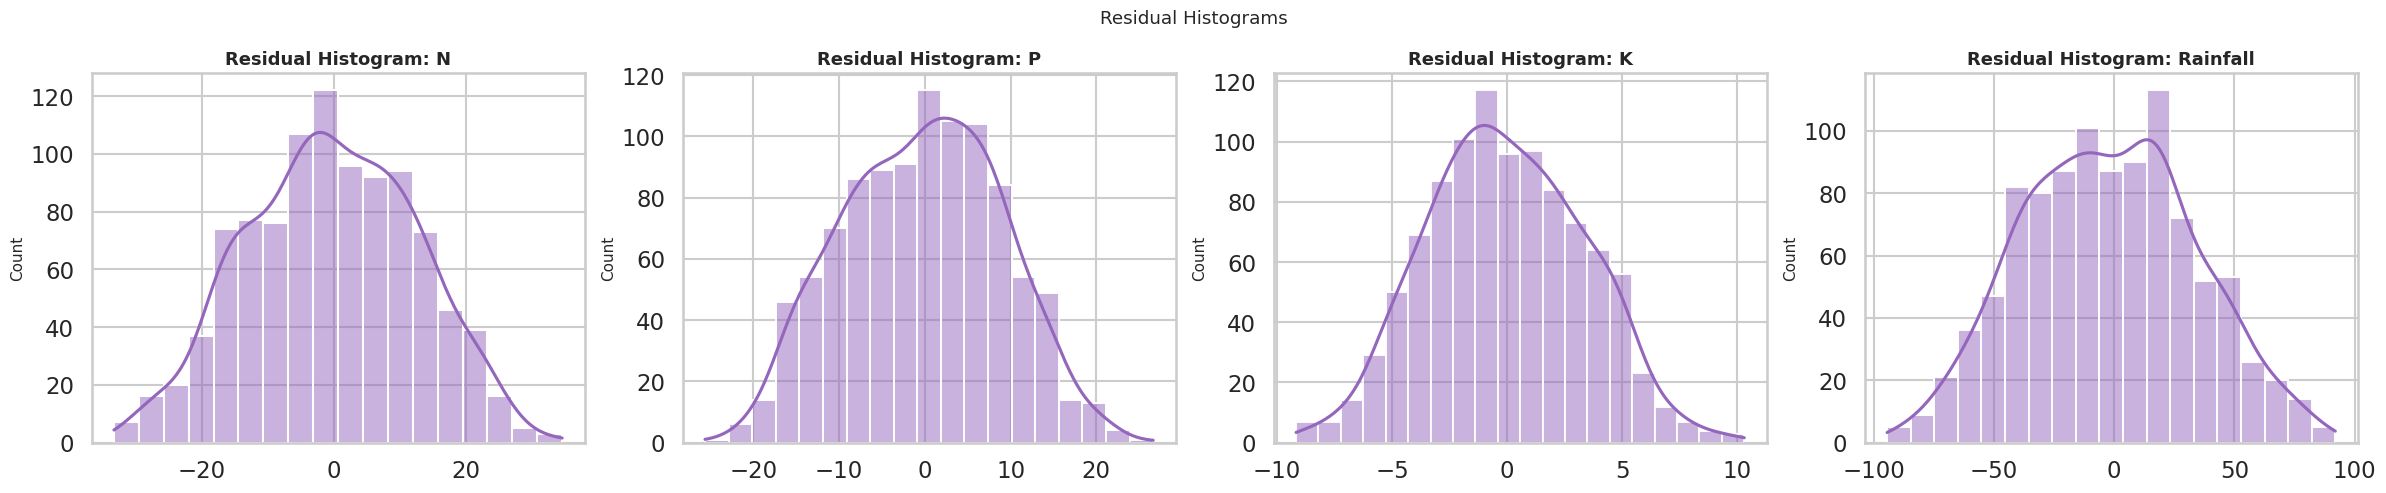

✓ Figure saved: ./output/phase_1_3/plots/19_residual_histogram.png


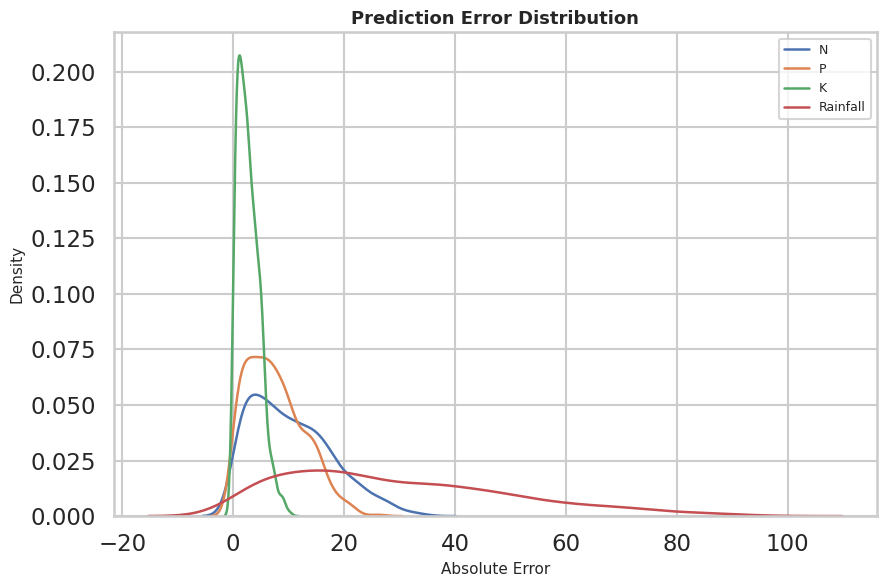

✓ Figure saved: ./output/phase_1_3/plots/20_prediction_error_distribution.png


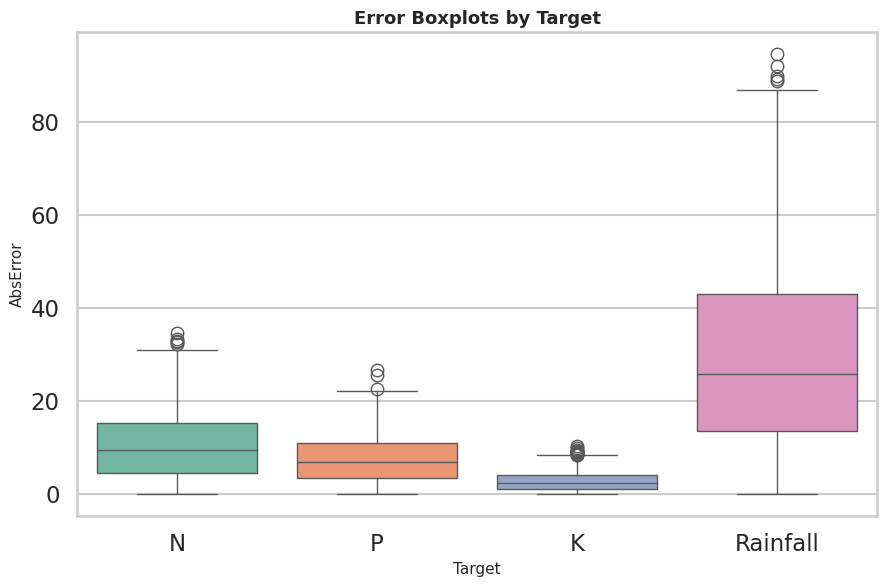

✓ Figure saved: ./output/phase_1_3/plots/21_error_boxplots.png

--- EXPLAINABILITY (SHAP) ---


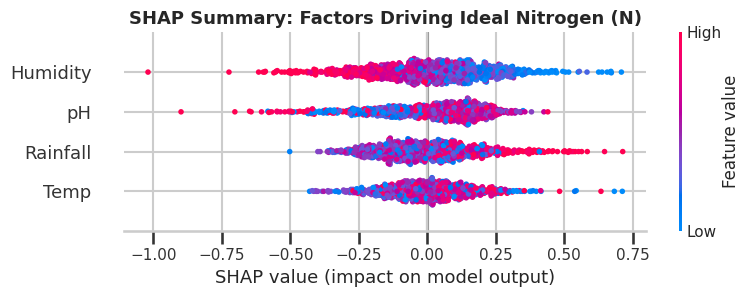

✓ Figure saved: ./output/phase_1_3/plots/22_shap_summary_N.png


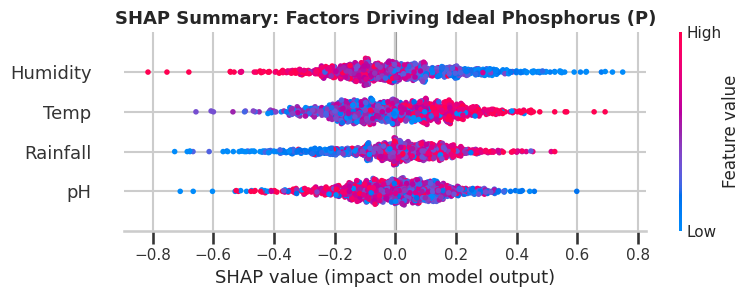

✓ Figure saved: ./output/phase_1_3/plots/23_shap_summary_P.png


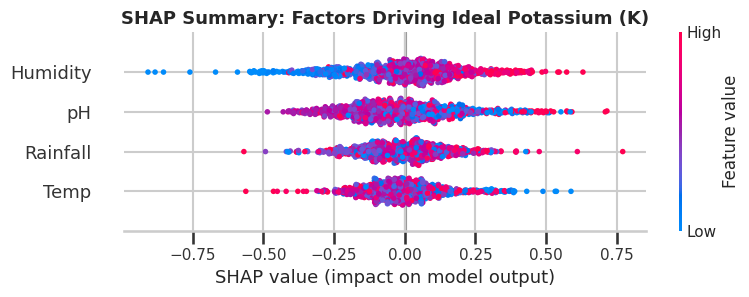

✓ Figure saved: ./output/phase_1_3/plots/24_shap_summary_K.png


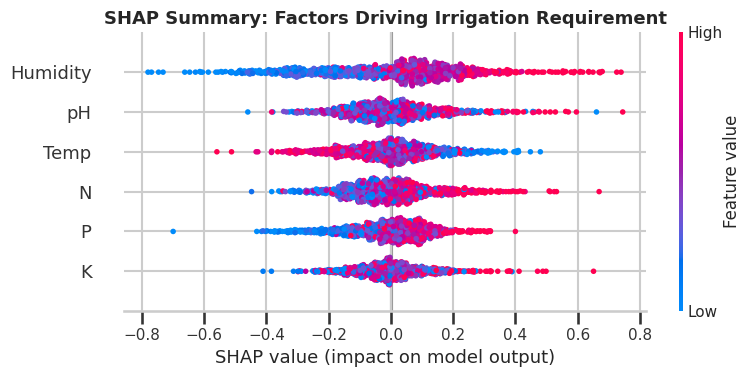

✓ Figure saved: ./output/phase_1_3/plots/25_shap_summary_irrigation.png


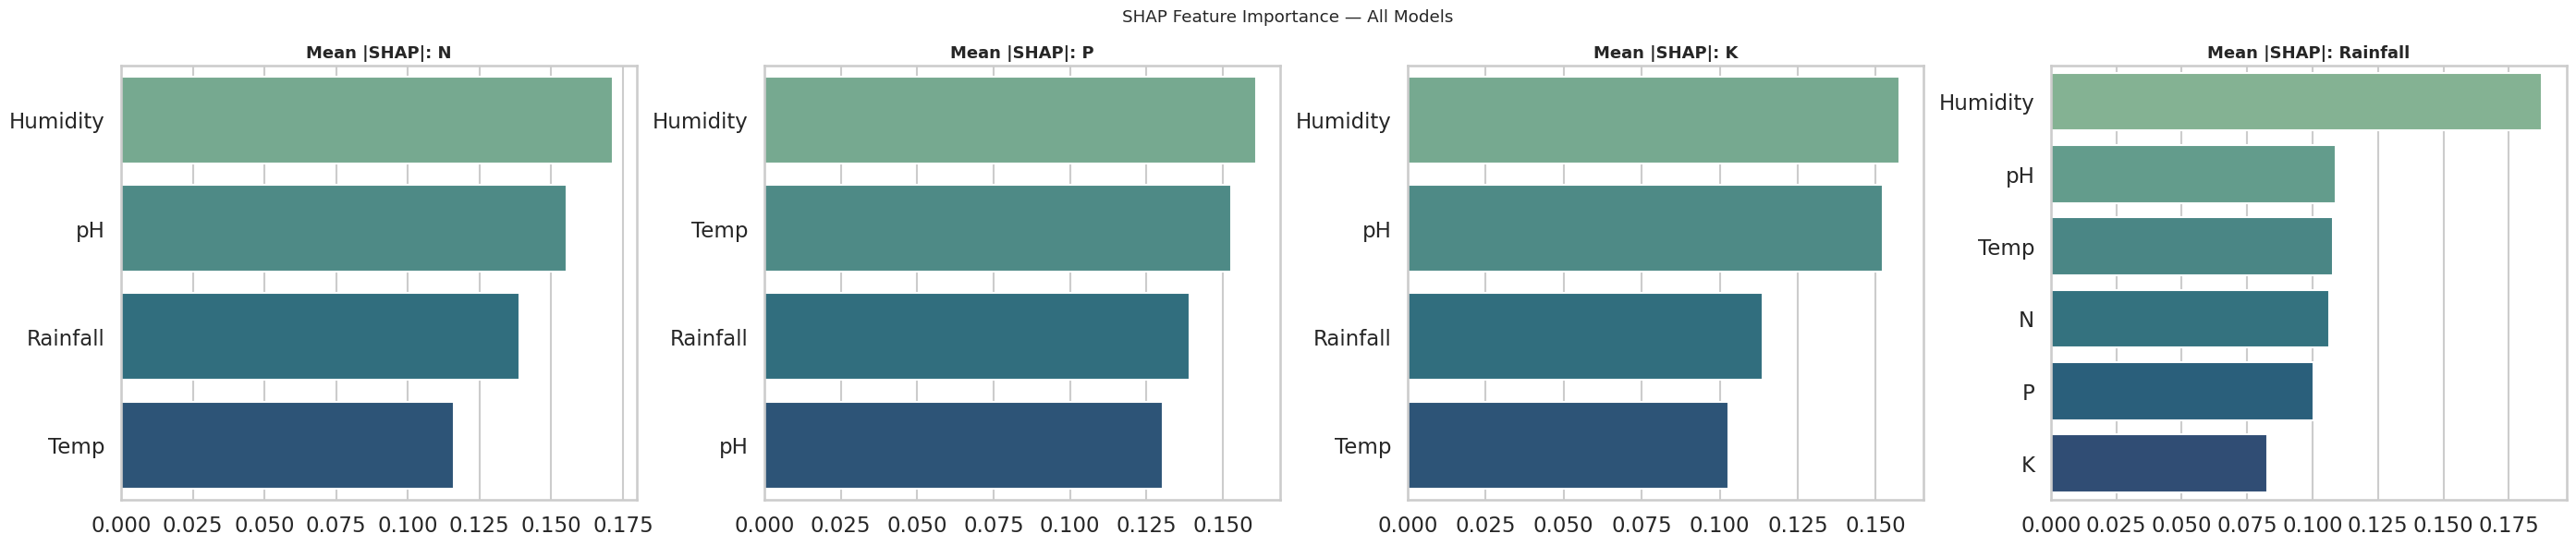

✓ Figure saved: ./output/phase_1_3/plots/26_shap_importance_bar_all.png

--- MODEL PERFORMANCE ---


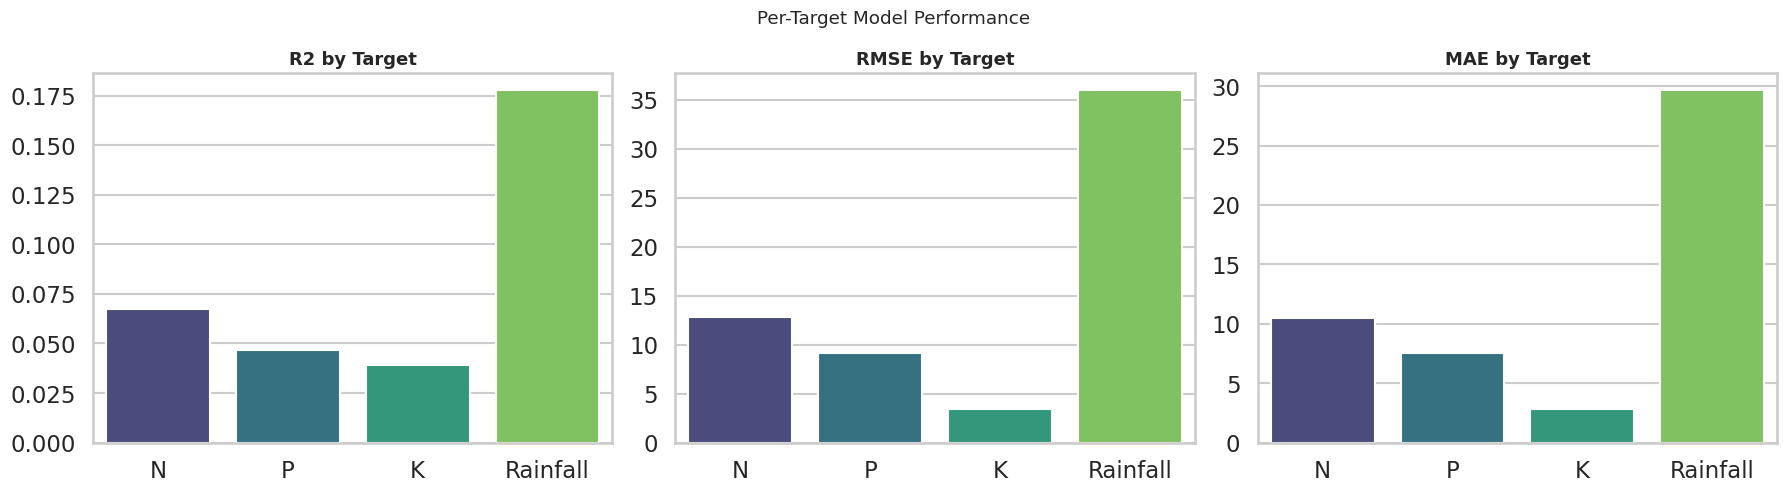

✓ Figure saved: ./output/phase_1_3/plots/27_per_target_metrics.png


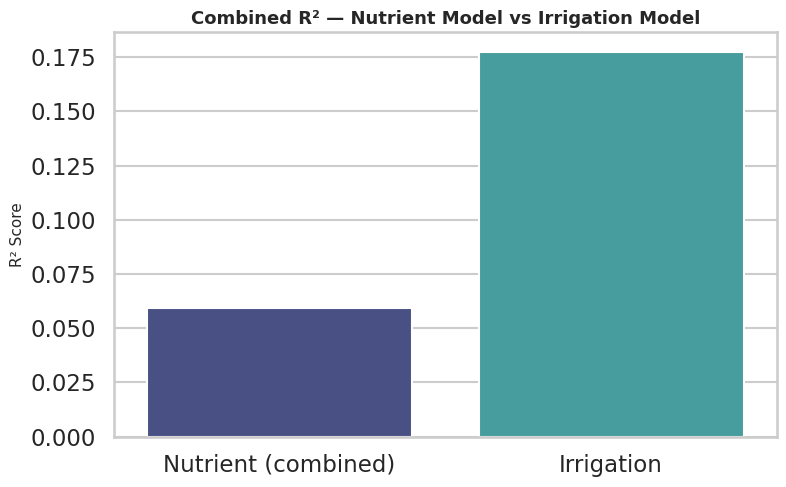

✓ Figure saved: ./output/phase_1_3/plots/28_combined_r2_comparison.png


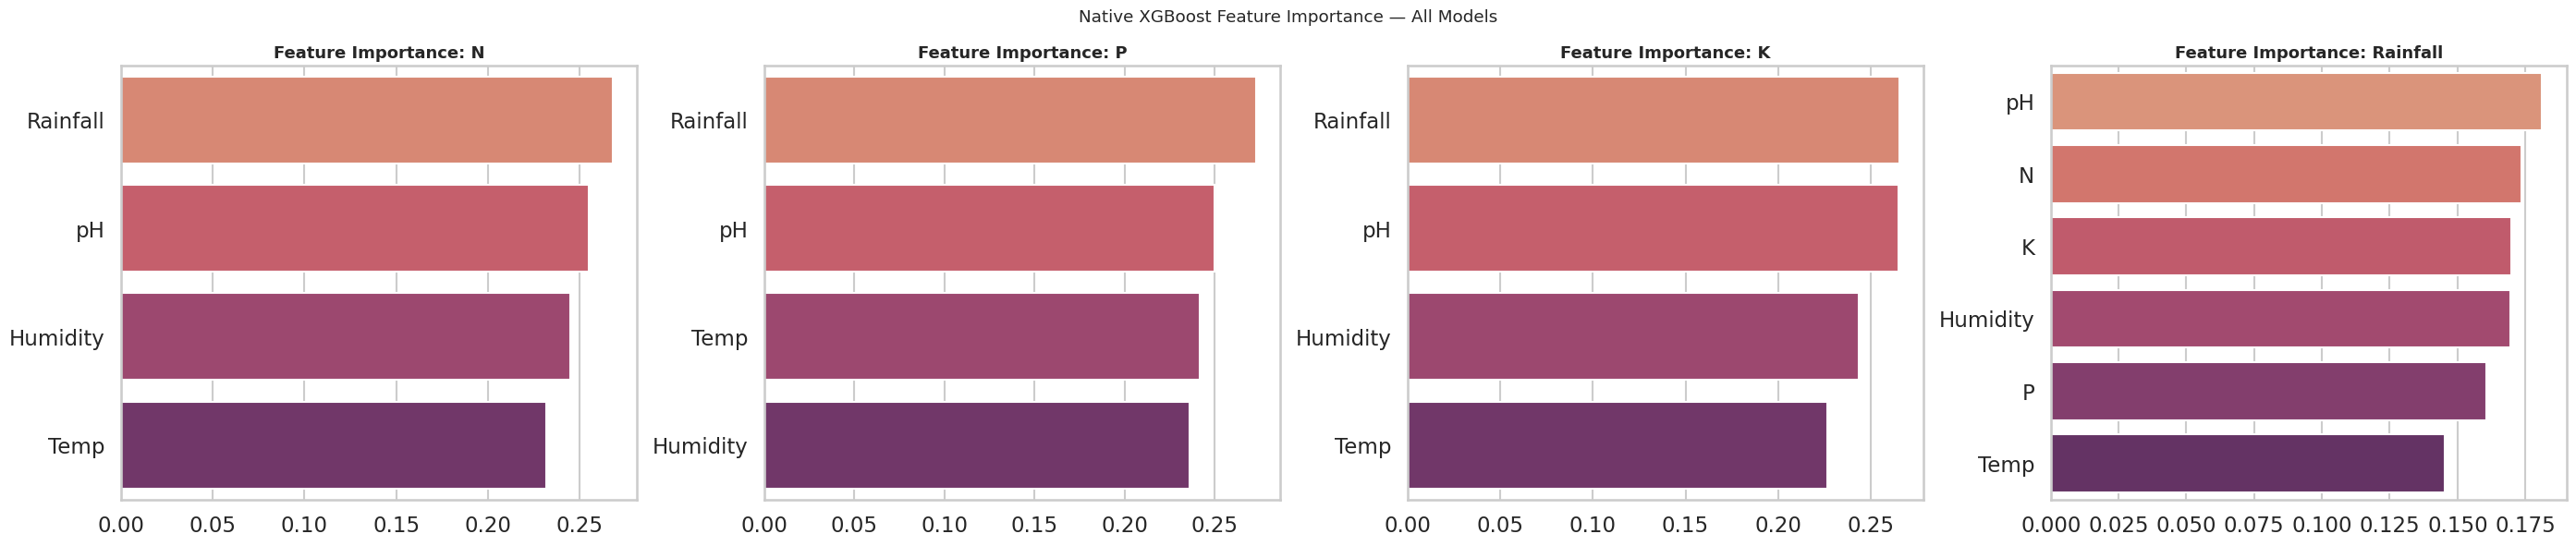

✓ Figure saved: ./output/phase_1_3/plots/29_feature_importance_all.png

--- FINAL SUMMARY DASHBOARD ---


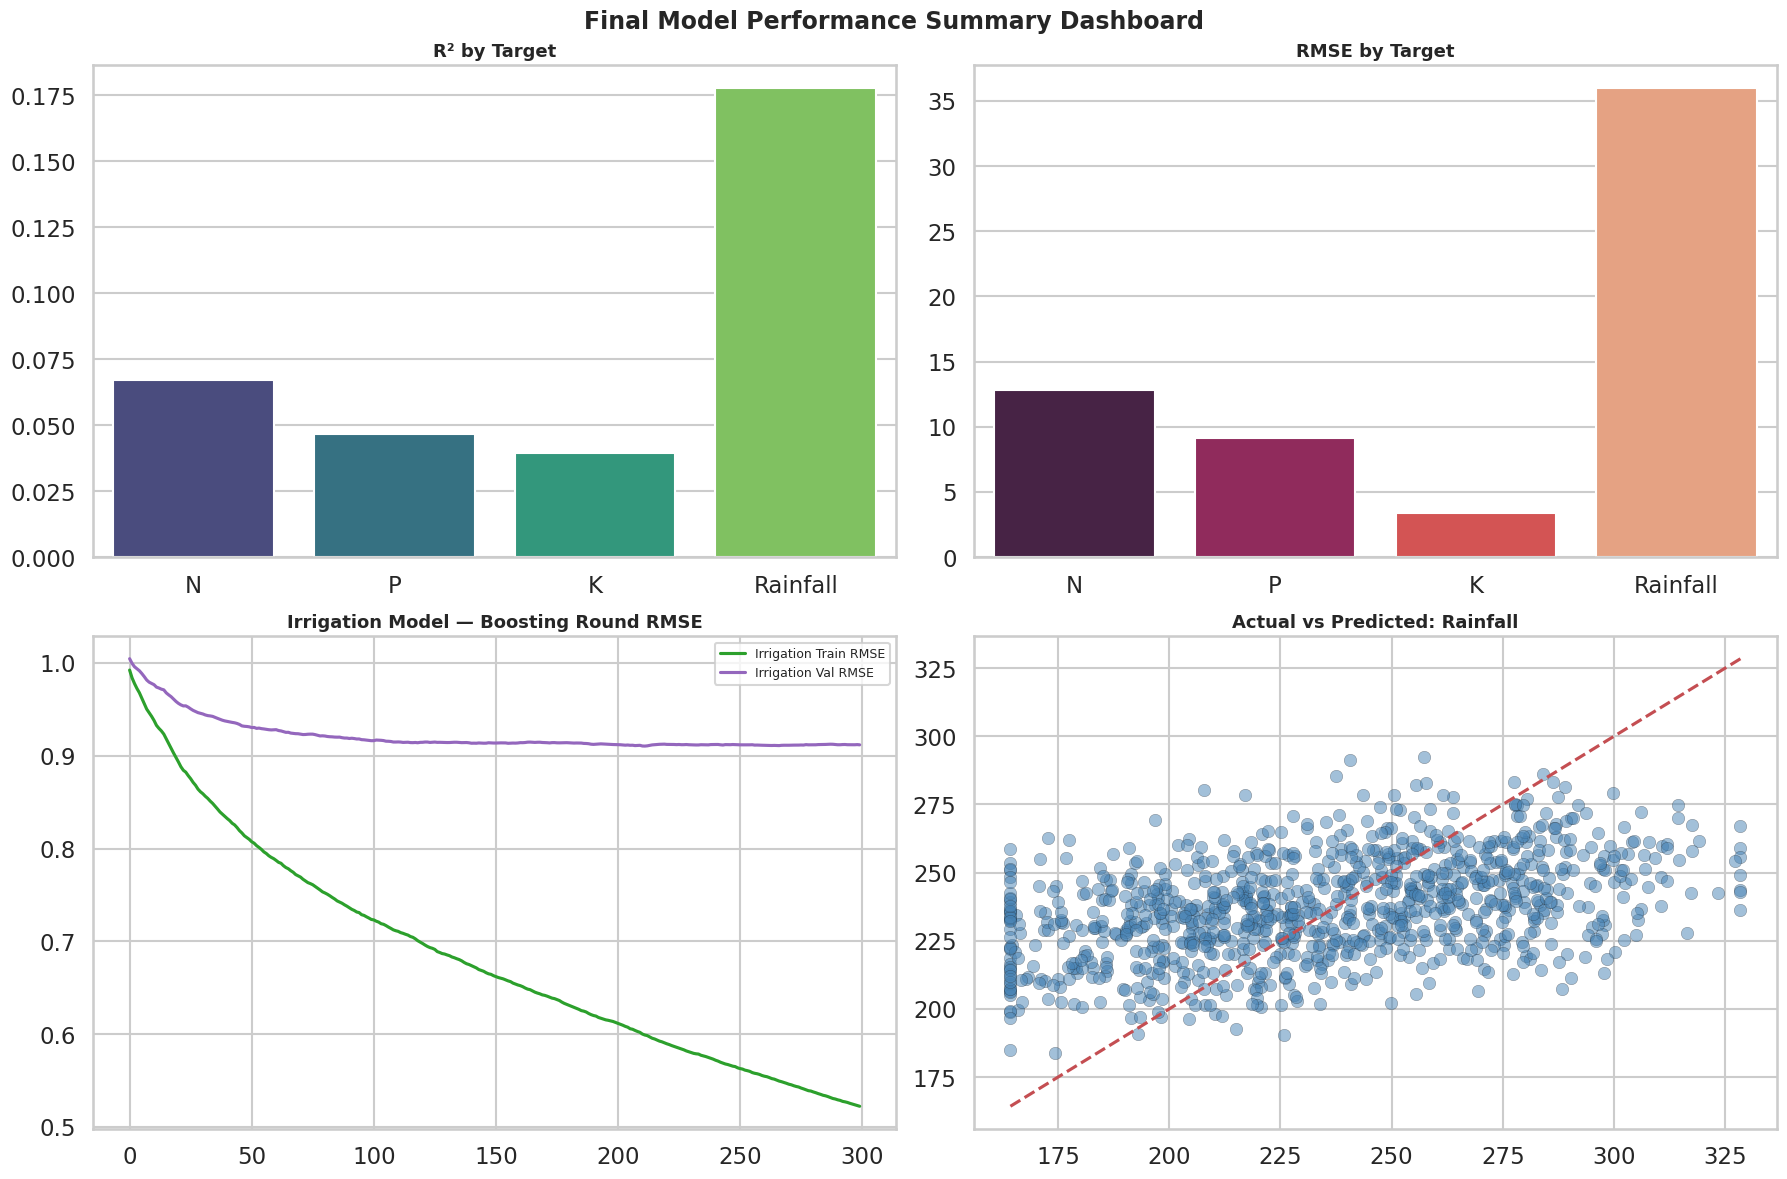

✓ Figure saved: ./output/phase_1_3/plots/30_final_summary_dashboard.png

ALL PUBLICATION-QUALITY VISUALIZATIONS EXPORTED TO: ./output/phase_1_3/plots


In [25]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "font.size": 11,
    "figure.dpi": 100,
    "savefig.dpi": 300,
})


VIZ_DIR = Config.PLOT_DIR
os.makedirs(VIZ_DIR, exist_ok=True)

def save_fig(fig, name):
    try:
        fig.tight_layout()
        plt.show()
        path = os.path.join(VIZ_DIR, f"{name}.png")
        fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
        plt.close(fig)
        print(f"✓ Figure saved: {path}")
    except Exception as e:
        print(f"✗ Could not save {name}: {e}")
        try:
            plt.close(fig)
        except Exception:
            pass

def safe_block(title):
    def deco(fn):
        def wrapper(*a, **kw):
            try:
                return fn(*a, **kw)
            except Exception as e:
                print(f"⚠ Skipped [{title}]: {e}")
        return wrapper
    return deco

numeric_cols = df_rice.columns.tolist()  # temperature, humidity, ph, rainfall, N, P, K

nut_feature_names = ['temperature', 'humidity', 'ph', 'rainfall']
nut_feature_labels = ['Temp', 'Humidity', 'pH', 'Rainfall']
irr_feature_names = ['temperature', 'humidity', 'ph', 'N', 'P', 'K']
irr_feature_labels = ['Temp', 'Humidity', 'pH', 'N', 'P', 'K']

nut_targets = ['N', 'P', 'K']  # column order in y_n_true / y_n_pred

# Per-target actual/predicted lookup (regenerated where necessary)
def get_actual_pred(target):
    if target in nut_targets:
        idx = nut_targets.index(target)
        return y_n_true[:, idx], y_n_pred[:, idx]
    if target == 'Rainfall':
        return y_i_true, y_i_pred
    return None, None

all_targets = nut_targets + ['Rainfall']

print("=" * 70)
print("PUBLICATION QUALITY VISUALIZATION BLOCK")
print("=" * 70)

print("\n--- DATASET ANALYSIS ---")

@safe_block("Feature Distributions")
def _d1():
    cols = numeric_cols
    ncols = 3
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for i, c in enumerate(cols):
        sns.histplot(df_rice[c].dropna(), kde=True, ax=axes[i], color="steelblue")
        axes[i].set_title(f"Distribution of {c}")
    for j in range(len(cols), len(axes)):
        axes[j].axis("off")
    fig.suptitle("Feature Distributions (Rice Subset)")
    save_fig(fig, "01_feature_distributions")
_d1()

@safe_block("Box Plots")
def _d2():
    cols = numeric_cols
    fig, ax = plt.subplots(figsize=(max(8, len(cols) * 1.2), 6))
    sns.boxplot(data=df_rice[cols], ax=ax, palette="Set2")
    ax.set_title("Box Plots of Numeric Features")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    save_fig(fig, "02_boxplots")
_d2()

@safe_block("Violin Plots")
def _d3():
    cols = numeric_cols
    fig, ax = plt.subplots(figsize=(max(8, len(cols) * 1.2), 6))
    sns.violinplot(data=df_rice[cols], ax=ax, palette="Set3")
    ax.set_title("Violin Plots of Numeric Features")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    save_fig(fig, "03_violinplots")
_d3()

@safe_block("KDE Distributions")
def _d4():
    fig, ax = plt.subplots(figsize=(9, 6))
    for c in numeric_cols:
        sns.kdeplot(df_rice[c].dropna(), ax=ax, label=c, linewidth=1.8)
    ax.set_title("KDE Distributions of Key Features")
    ax.legend()
    save_fig(fig, "04_kde_distributions")
_d4()

@safe_block("Correlation Heatmap")
def _d5():
    corr = df_rice[numeric_cols].corr()
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax, square=True)
    ax.set_title("Feature Correlation Heatmap (Rice)")
    save_fig(fig, "05_correlation_heatmap")
_d5()

@safe_block("Pairplot")
def _d6():
    g = sns.pairplot(df_rice[numeric_cols].dropna(), diag_kind="kde", corner=True,
                      plot_kws={"alpha": 0.5, "s": 15})
    g.fig.suptitle("Pairwise Feature Relationships", y=1.02)
    save_fig(g.fig, "06_pairplot")
_d6()

@safe_block("Missing Value Heatmap")
def _d7():
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(df_rice.isnull(), cbar=False, cmap="viridis", ax=ax)
    ax.set_title("Missing Value Heatmap")
    save_fig(fig, "07_missing_value_heatmap")
_d7()

@safe_block("Feature Statistics Table")
def _d8():
    stats = df_rice[numeric_cols].describe().T
    fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(numeric_cols))))
    ax.axis("off")
    tbl = ax.table(cellText=np.round(stats.values, 2), rowLabels=stats.index,
                   colLabels=stats.columns, loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1, 1.5)
    ax.set_title("Feature Statistics Summary", pad=20)
    save_fig(fig, "08_feature_statistics")
_d8()

@safe_block("Feature Variance Comparison")
def _d9():
    variances = df_rice[numeric_cols].var().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(x=variances.values, y=variances.index, ax=ax, palette="mako")
    ax.set_title("Feature Variance Comparison")
    ax.set_xlabel("Variance")
    save_fig(fig, "09_feature_variance_comparison")
_d9()

print("\n--- SYNTHETIC DATA ANALYSIS ---")

@safe_block("Original vs Synthetic Distributions")
def _sd1():
    cols = numeric_cols
    ncols = 3
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for i, c in enumerate(cols):
        sns.histplot(df_rice[c].dropna(), color="steelblue", label="Original",
                     stat="density", kde=True, ax=axes[i], alpha=0.5)
        sns.histplot(df_synth[c].dropna(), color="darkorange", label="Synthetic",
                     stat="density", kde=True, ax=axes[i], alpha=0.5)
        axes[i].set_title(c)
        axes[i].legend()
    for j in range(len(cols), len(axes)):
        axes[j].axis("off")
    fig.suptitle("Original vs Synthetic Distributions")
    save_fig(fig, "10_original_vs_synthetic_distributions")
_sd1()

@safe_block("Original vs Synthetic KDE Comparison")
def _sd2():
    cols = numeric_cols[:4]
    fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 5))
    axes = np.array(axes).reshape(-1)
    for i, c in enumerate(cols):
        sns.kdeplot(df_rice[c].dropna(), ax=axes[i], label="Original", color="steelblue", linewidth=1.8)
        sns.kdeplot(df_synth[c].dropna(), ax=axes[i], label="Synthetic", color="darkorange", linewidth=1.8)
        axes[i].set_title(c)
        axes[i].legend()
    fig.suptitle("Original vs Synthetic KDE Comparison")
    save_fig(fig, "11_original_vs_synthetic_kde")
_sd2()

@safe_block("Original vs Synthetic Boxplots")
def _sd3():
    cols = numeric_cols
    combined = pd.concat([
        df_rice[cols].assign(Source="Original"),
        df_synth[cols].assign(Source="Synthetic")
    ], ignore_index=True)
    melted = combined.melt(id_vars="Source", var_name="Feature", value_name="Value")
    fig, ax = plt.subplots(figsize=(max(10, len(cols) * 1.5), 6))
    sns.boxplot(data=melted, x="Feature", y="Value", hue="Source", ax=ax, palette="Set2")
    ax.set_title("Original vs Synthetic Boxplots")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    save_fig(fig, "12_original_vs_synthetic_boxplots")
_sd3()

@safe_block("Statistical Comparison Chart")
def _sd4():
    cols = numeric_cols
    orig_mean = df_rice[cols].mean()
    synth_mean = df_synth[cols].mean()
    x = np.arange(len(cols))
    width = 0.35
    fig, ax = plt.subplots(figsize=(max(10, len(cols) * 1.2), 6))
    ax.bar(x - width / 2, orig_mean.values, width, label="Original", color="steelblue")
    ax.bar(x + width / 2, synth_mean.values, width, label="Synthetic", color="darkorange")
    ax.set_xticks(x)
    ax.set_xticklabels(cols, rotation=45, ha="right")
    ax.set_title("Statistical Comparison: Original vs Synthetic (Mean)")
    ax.legend()
    save_fig(fig, "13_statistical_comparison")
_sd4()

print("\n--- MODEL TRAINING ---")

def _get_evals_result(fitted_model):
    """Pull train/val RMSE curves out of an already-fitted XGBoost model."""
    res = fitted_model.evals_result()
    if not res:
        return None, None
    keys = list(res.keys())
    train_key = keys[0]
    val_key = keys[1] if len(keys) > 1 else keys[0]
    metric_key = list(res[train_key].keys())[0]  # usually 'rmse'
    tr = res[train_key][metric_key]
    va = res[val_key][metric_key]
    return tr, va

@safe_block("Irrigation Model Training RMSE")
def _mt1():
    # train_rmse / val_rmse already computed for best_irrigation_model in the notebook
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(train_rmse, label="Train RMSE", color="#1f77b4")
    ax.plot(val_rmse, label="Val RMSE", color="#d62728")
    ax.set_title("Irrigation Model — RMSE per Boosting Round")
    ax.set_xlabel("Boosting Round"); ax.set_ylabel("RMSE")
    ax.legend()
    save_fig(fig, "14_irrigation_rmse_curve")
_mt1()

@safe_block("Nutrient Models Training RMSE (regenerated from evals_result)")
def _mt2():
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, name in enumerate(nut_targets):
        tr, va = _get_evals_result(nutrient_models[name])
        if tr is None:
            axes[i].axis("off")
            continue
        axes[i].plot(tr, label="Train RMSE", color="#1f77b4")
        axes[i].plot(va, label="Val RMSE", color="#d62728")
        axes[i].set_title(f"Nutrient Model: {name}")
        axes[i].set_xlabel("Boosting Round"); axes[i].set_ylabel("RMSE")
        axes[i].legend()
    fig.suptitle("Nutrient Models — RMSE per Boosting Round")
    save_fig(fig, "15_nutrient_rmse_curves")
_mt2()

@safe_block("All Models RMSE Convergence Overlay")
def _mt3():
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(val_rmse, label="Irrigation (val)", linewidth=1.8)
    for name in nut_targets:
        _, va = _get_evals_result(nutrient_models[name])
        if va is not None:
            ax.plot(va, label=f"{name} (val)", linewidth=1.8)
    ax.set_title("Validation RMSE Convergence — All Models")
    ax.set_xlabel("Boosting Round"); ax.set_ylabel("RMSE")
    ax.legend()
    save_fig(fig, "16_rmse_convergence_all_models")
_mt3()

print("\n--- MODEL EVALUATION ---")

@safe_block("Actual vs Predicted (all targets)")
def _me1():
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    colors = {"N": "#1f77b4", "P": "#ff7f0e", "K": "#2ca02c", "Rainfall": "#d62728"}
    for i, target in enumerate(all_targets):
        yt, yp = get_actual_pred(target)
        axes[i].scatter(yt, yp, alpha=0.5, color=colors[target], edgecolor="k", linewidth=0.3)
        lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
        axes[i].plot(lims, lims, "r--", label="Ideal")
        axes[i].set_title(f"Actual vs Predicted: {target}")
        axes[i].set_xlabel("Actual"); axes[i].set_ylabel("Predicted")
        axes[i].legend()
    fig.suptitle("Actual vs Predicted — All Targets")
    save_fig(fig, "17_actual_vs_predicted_all")
_me1()

@safe_block("Residual Plots (regenerated)")
def _me2():
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    for i, target in enumerate(all_targets):
        yt, yp = get_actual_pred(target)
        residuals = yt - yp
        axes[i].scatter(yp, residuals, alpha=0.5, color="steelblue", edgecolor="k", linewidth=0.3)
        axes[i].axhline(0, color="red", linestyle="--")
        axes[i].set_title(f"Residuals: {target}")
        axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("Residual")
    fig.suptitle("Residual Plots (computed from true - predicted)")
    save_fig(fig, "18_residual_plots")
_me2()

@safe_block("Residual Histograms (regenerated)")
def _me3():
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    for i, target in enumerate(all_targets):
        yt, yp = get_actual_pred(target)
        residuals = yt - yp
        sns.histplot(residuals, kde=True, ax=axes[i], color="#9467bd")
        axes[i].set_title(f"Residual Histogram: {target}")
    fig.suptitle("Residual Histograms")
    save_fig(fig, "19_residual_histogram")
_me3()

@safe_block("Prediction Error Distribution (regenerated)")
def _me4():
    fig, ax = plt.subplots(figsize=(9, 6))
    for target in all_targets:
        yt, yp = get_actual_pred(target)
        errors = np.abs(yt - yp)
        sns.kdeplot(errors, ax=ax, label=target, linewidth=1.8)
    ax.set_title("Prediction Error Distribution")
    ax.set_xlabel("Absolute Error")
    ax.legend()
    save_fig(fig, "20_prediction_error_distribution")
_me4()

@safe_block("Error Boxplots (regenerated)")
def _me5():
    records = []
    for target in all_targets:
        yt, yp = get_actual_pred(target)
        for e in np.abs(yt - yp):
            records.append({"Target": target, "AbsError": e})
    err_df = pd.DataFrame(records)
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.boxplot(data=err_df, x="Target", y="AbsError", ax=ax, palette="Set2")
    ax.set_title("Error Boxplots by Target")
    save_fig(fig, "21_error_boxplots")
_me5()

print("\n--- EXPLAINABILITY (SHAP) ---")

@safe_block("Regenerate missing SHAP values (P, K)")
def _regen_shap():
    global explainer_p, shap_values_p, explainer_k, shap_values_k
    explainer_p = shap.TreeExplainer(nutrient_models['P'])
    shap_values_p = explainer_p.shap_values(X_n_test)
    explainer_k = shap.TreeExplainer(nutrient_models['K'])
    shap_values_k = explainer_k.shap_values(X_n_test)
_regen_shap()

@safe_block("SHAP Summary Plot: Nitrogen (N)")
def _sh1():
    fig = plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_n, X_n_test, feature_names=nut_feature_labels, show=False)
    plt.title("SHAP Summary: Factors Driving Ideal Nitrogen (N)")
    save_fig(plt.gcf(), "22_shap_summary_N")
_sh1()

@safe_block("SHAP Summary Plot: Phosphorus (P)")
def _sh2():
    fig = plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_p, X_n_test, feature_names=nut_feature_labels, show=False)
    plt.title("SHAP Summary: Factors Driving Ideal Phosphorus (P)")
    save_fig(plt.gcf(), "23_shap_summary_P")
_sh2()

@safe_block("SHAP Summary Plot: Potassium (K)")
def _sh3():
    fig = plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_k, X_n_test, feature_names=nut_feature_labels, show=False)
    plt.title("SHAP Summary: Factors Driving Ideal Potassium (K)")
    save_fig(plt.gcf(), "24_shap_summary_K")
_sh3()

@safe_block("SHAP Summary Plot: Irrigation (Rainfall)")
def _sh4():
    fig = plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_irr, X_i_test, feature_names=irr_feature_labels, show=False)
    plt.title("SHAP Summary: Factors Driving Irrigation Requirement")
    save_fig(plt.gcf(), "25_shap_summary_irrigation")
_sh4()

@safe_block("SHAP Feature Importance Bar (all 4 models)")
def _sh5():
    fig, axes = plt.subplots(1, 4, figsize=(28, 6))
    shap_map = {
        "N": (shap_values_n, nut_feature_labels, X_n_test),
        "P": (shap_values_p, nut_feature_labels, X_n_test),
        "K": (shap_values_k, nut_feature_labels, X_n_test),
        "Rainfall": (shap_values_irr, irr_feature_labels, X_i_test),
    }
    for i, (target, (sv, labels, X)) in enumerate(shap_map.items()):
        plt.sca(axes[i])
        mean_abs = np.abs(sv).mean(axis=0)
        order = np.argsort(mean_abs)[::-1]
        sns.barplot(x=mean_abs[order], y=np.array(labels)[order], ax=axes[i], palette="crest")
        axes[i].set_title(f"Mean |SHAP|: {target}")
    fig.suptitle("SHAP Feature Importance — All Models")
    save_fig(fig, "26_shap_importance_bar_all")
_sh5()

print("\n--- MODEL PERFORMANCE ---")

@safe_block("Per-Target R² / RMSE / MAE (regenerated where needed)")
def _mp1():
    
    metrics = {}
    for i, name in enumerate(nut_targets):
        yt, yp = y_n_true[:, i], y_n_pred[:, i]
        metrics[name] = {
            "R2": r2_score(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "MAE": mean_absolute_error(yt, yp),
        }
    metrics["Rainfall"] = {"R2": irr_r2, "RMSE": irr_rmse, "MAE": irr_mae}

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, metric in zip(axes, ["R2", "RMSE", "MAE"]):
        vals = [metrics[t][metric] for t in all_targets]
        sns.barplot(x=all_targets, y=vals, ax=ax, palette="viridis")
        ax.set_title(f"{metric} by Target")
    fig.suptitle("Per-Target Model Performance")
    save_fig(fig, "27_per_target_metrics")
    return metrics
metrics_by_target = _mp1()

@safe_block("Combined Model Performance Summary (as computed in notebook)")
def _mp2():
    fig, ax = plt.subplots(figsize=(8, 5))
    labels = ["Nutrient (combined)", "Irrigation"]
    r2_vals = [nut_r2, irr_r2]
    sns.barplot(x=labels, y=r2_vals, ax=ax, palette="mako")
    ax.set_title("Combined R² — Nutrient Model vs Irrigation Model")
    ax.set_ylabel("R² Score")
    save_fig(fig, "28_combined_r2_comparison")
_mp2()

@safe_block("Native XGBoost Feature Importance (N, P, K, Irrigation)")
def _mp3():
    fig, axes = plt.subplots(1, 4, figsize=(28, 6))
    models_map = {
        "N": (nutrient_models["N"], nut_feature_labels),
        "P": (nutrient_models["P"], nut_feature_labels),
        "K": (nutrient_models["K"], nut_feature_labels),
        "Rainfall": (best_irrigation_model, irr_feature_labels),
    }
    for i, (target, (mdl, labels)) in enumerate(models_map.items()):
        importances = mdl.feature_importances_
        order = np.argsort(importances)[::-1]
        sns.barplot(x=np.array(importances)[order], y=np.array(labels)[order],
                    ax=axes[i], palette="flare")
        axes[i].set_title(f"Feature Importance: {target}")
    fig.suptitle("Native XGBoost Feature Importance — All Models")
    save_fig(fig, "29_feature_importance_all")
_mp3()

print("\n--- FINAL SUMMARY DASHBOARD ---")

@safe_block("Final Summary Dashboard")
def _fd1():
    fig = plt.figure(figsize=(18, 12))
    gs = fig.add_gridspec(2, 2)

    ax1 = fig.add_subplot(gs[0, 0])
    r2_vals = [metrics_by_target[t]["R2"] for t in all_targets]
    sns.barplot(x=all_targets, y=r2_vals, ax=ax1, palette="viridis")
    ax1.set_title("R² by Target")

    ax2 = fig.add_subplot(gs[0, 1])
    rmse_vals = [metrics_by_target[t]["RMSE"] for t in all_targets]
    sns.barplot(x=all_targets, y=rmse_vals, ax=ax2, palette="rocket")
    ax2.set_title("RMSE by Target")

    ax3 = fig.add_subplot(gs[1, 0])
    ax3.plot(train_rmse, label="Irrigation Train RMSE", color="#2ca02c")
    ax3.plot(val_rmse, label="Irrigation Val RMSE", color="#9467bd")
    ax3.set_title("Irrigation Model — Boosting Round RMSE")
    ax3.legend()

    ax4 = fig.add_subplot(gs[1, 1])
    yt, yp = get_actual_pred("Rainfall")
    ax4.scatter(yt, yp, alpha=0.5, color="steelblue", edgecolor="k", linewidth=0.3)
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax4.plot(lims, lims, "r--")
    ax4.set_title("Actual vs Predicted: Rainfall")

    fig.suptitle("Final Model Performance Summary Dashboard", fontsize=17, fontweight="bold")
    save_fig(fig, "30_final_summary_dashboard")
_fd1()

print("\n" + "=" * 70)
print("ALL PUBLICATION-QUALITY VISUALIZATIONS EXPORTED TO:", VIZ_DIR)
print("=" * 70)

In [26]:
import os
import zipfile
from pathlib import Path

print("=" * 70)
print("Creating Final Project ZIP...")
print("=" * 70)

ZIP_NAME = "Phase_1_3_Nutrient_Irrigation_Output.zip"

INCLUDE_EXTENSIONS = {
    ".pth",
    ".pt",
    ".json",
    ".pkl",
    ".pickle",
    ".model",
    ".bin",
    ".txt",
    ".csv",
    ".xlsx",
    ".pdf",
    ".png",
    ".jpg",
    ".jpeg",
    ".svg",
    ".html",
    ".log",
    ".yaml",
    ".yml"
}

# Folders to skip
SKIP_DIRS = {
    ".git",
    "__pycache__",
    ".ipynb_checkpoints"
}

files_added = 0

with zipfile.ZipFile(ZIP_NAME, "w", compression=zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, files in os.walk("."):

        dirs[:] = [d for d in dirs if d not in SKIP_DIRS]

        for file in files:

            filepath = os.path.join(root, file)
            ext = Path(file).suffix.lower()

            if ext in INCLUDE_EXTENSIONS:
                arcname = os.path.relpath(filepath, ".")
                zipf.write(filepath, arcname)
                files_added += 1

print(f"\nZIP File Created Successfully : {ZIP_NAME}")
print(f"Total Files Added : {files_added}")

print("\nIncluded File Types:")
print(", ".join(sorted(INCLUDE_EXTENSIONS)))


Creating Final Project ZIP...

ZIP File Created Successfully : Phase_1_3_Nutrient_Irrigation_Output.zip
Total Files Added : 45

Included File Types:
.bin, .csv, .html, .jpeg, .jpg, .json, .log, .model, .pdf, .pickle, .pkl, .png, .pt, .pth, .svg, .txt, .xlsx, .yaml, .yml
